# Actividad 3 — Data Wrangling: Room Occupancy Estimation

* **Nombre:** Luis Manuel Velasco Iglesias
* **Matrícula:** A00226599
* **Curso:** TC5044.10 MLOps

**Objetivo.** `modified.csv` es una copia perturbada del dataset *Room Occupancy Estimation* (UCI).
En este notebook se diagnostica su calidad, se limpia con tres estrategias y se compara cada
resultado contra el dataset original sin duplicados.

**Regla de trabajo.** Todas las decisiones de limpieza se toman solo con `modified.csv` y
conocimiento del dominio. El archivo `original.csv` se usa únicamente al final, para la
auditoría y la EDA comparativa.

**Estructura de carpetas esperada** (rutas relativas a este notebook):

    notebooks/A03_A00226599.ipynb
    data/raw/room-occupancy-estimation/original.csv
    data/raw/room-occupancy-estimation/modified.csv
    data/raw/room-occupancy-estimation/metadata.json
    data/interim/room-occupancy-estimation/       <- línea base sin duplicados (se genera aquí)
    data/processed/room-occupancy-estimation/    <- un archivo limpio por estrategia (se genera aquí)

## El dataset: Room Occupancy Estimation

Dataset público del repositorio de UCI que registra las condiciones de **una sola habitación**
(6 m × 4.6 m, sin calefacción ni aire acondicionado) para estimar **cuántas personas hay en ella**,
de 0 a 3, a partir de sensores ambientales en lugar de cámaras.

Siete nodos de sensores colocados en distintos puntos del cuarto envían una lectura **cada 30 segundos**.
Cada fila es una "foto" de todos los sensores en un mismo instante. Los datos se tomaron en sesiones
de varios días entre diciembre de 2017 y enero de 2018, y la ocupación real se registró manualmente.

| Columnas | Sensor | Unidad |
|---|---|---|
| `Date`, `Time` | Marca de tiempo de la lectura | YYYY/MM/DD, HH:MM:SS |
| `S1_Temp` … `S4_Temp` | Temperatura (nodos 1 a 4) | °C |
| `S1_Light` … `S4_Light` | Luz (nodos 1 a 4) | lux |
| `S1_Sound` … `S4_Sound` | Sonido: salida del micrófono leída por un ADC (nodos 1 a 4) | volts |
| `S5_CO2` | Concentración de CO2 (nodo 5) | ppm |
| `S5_CO2_Slope` | Pendiente del CO2 en una ventana deslizante (nodo 5) | — |
| `S6_PIR`, `S7_PIR` | Detección de movimiento (nodos 6 y 7) | binario (0/1) |
| `Room_Occupancy_Count` | **Variable objetivo:** número de personas en la habitación | 0 a 3 |

**Archivos de esta actividad**
- `original.csv`: el dataset publicado (10,129 lecturas, 19 columnas).
- `modified.csv`: una copia deliberadamente corrompida (10,331 filas, 20 columnas) con espacios,
  tokens inválidos, valores faltantes, valores imposibles, filas duplicadas y una columna de ruido.
  Es el archivo que se diagnostica y limpia en este notebook.

> **Fuente:** A. P. Singh, V. Jain, S. Chaudhari, F. A. Kraemer, S. Werner y V. Garg,
"Machine Learning-Based Occupancy Estimation Using Multivariate Sensor Nodes",
*2018 IEEE Globecom Workshops*. Dataset: [UCI ML Repository](https://archive.ics.uci.edu/dataset/864/room+occupancy+estimation),
DOI [10.24432/C5P605](https://doi.org/10.24432/C5P605), licencia CC BY 4.0.

### 1. Configuracion 

In [1]:
# ------ Import Libraries ----------

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

from IPython.display import display

In [2]:
# ------ File Paths ----------

# Todas las rutas se definen aquí. Si la estructura cambia, solo se edita PROJECT_DIR.
PROJECT_DIR = Path("..")  # el notebook vive en notebooks/
RAW_DIR = PROJECT_DIR / "data" / "raw" / "room-occupancy-estimation"
INTERIM_DIR = PROJECT_DIR / "data" / "interim"/ "room-occupancy-estimation"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"/"room-occupancy-estimation"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"

MODIFIED_PATH = RAW_DIR / "modified.csv"
ORIGINAL_PATH = RAW_DIR / "original.csv"        # solo para auditoría y EDA comparativa
METADATA_PATH = RAW_DIR / "metadata.json"
BASELINE_PATH = INTERIM_DIR / "original_no_duplicates.csv"

CLEAN_A_PATH = PROCESSED_DIR / "cleaned_dropna.csv"        # estrategia A
CLEAN_B_PATH = PROCESSED_DIR / "cleaned_interpolated.csv"  # estrategia B
CLEAN_C_PATH = PROCESSED_DIR / "cleaned_median.csv"        # estrategia C

# Crear las carpetas de salida y fallar pronto si faltan los datos de entrada
for folder in (INTERIM_DIR, PROCESSED_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

for path in (MODIFIED_PATH, ORIGINAL_PATH):
    if not path.exists():
        raise FileNotFoundError(f"No se encontró {path}. Revisa la estructura de carpetas descrita al inicio.")

### 2. Carga segura de los datos

El archivo se lee completo como texto (`dtype=str`). Si pandas infiere los tipos, un solo
token como `"?"` convierte la columna entera a `object` y los problemas quedan ocultos.
Con `keep_default_na=False`, cadenas como `"NULL"` o `"N/A"` llegan como texto literal,
de modo que las pruebas de diagnóstico puedan contarlas en lugar de que desaparezcan como NaN.


In [3]:
raw_df = pd.read_csv(MODIFIED_PATH, dtype=str, keep_default_na=False)

print(f"Filas: {raw_df.shape[0]:,}   Columnas: {raw_df.shape[1]}")
raw_df.head()

Filas: 10,331   Columnas: 20


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count,mixed_type_col
0,2017/12/22,10:49:41,24.94,345.75,24.56,25.38,121.0,34.0,53.0,40.0,0.08,0.19,0.06,0.06,390.0,0.769230769231,0.0,0.0,1.0,599
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121.0,33.0,53.0,40.0,0.93,0.05,0.06,0.06,390.0,0.646153846154,0.0,0.0,1.0,
2,2017/12/22,10:50:42,25.0,24.75,24.5,25.44,121.0,34.0,53.0,40.0,0.43,0.11,0.08,0.06,390.0,0.519230769231,0.0,0.0,1.0,unknown
3,2017/12/22,10:51:13,25.0,24.75,24.56,25.44,121.0,34.0,53.0,40.0,0.41,0.1,0.1,0.09,390.0,0.388461538462,0.0,0.0,1.0,584
4,2017/12/22,10:51:44,25.0,24.75,24.56,25.44,121.0,34.0,54.0,40.0,0.18,0.06,0.06,0.06,390.0,0.253846153846,0.0,0.0,1.0,bad


In [4]:
# Metadatos de la perturbación: solo como referencia, no se usan para decidir la limpieza
metadata = json.loads(METADATA_PATH.read_text())
metadata["rates"]

{'dup_rate': 0.02,
 'nan_rate': 0.01,
 'outlier_rate': 0.01,
 'bad_token_rate': 0.005,
 'obj_noise_rate': 0.05,
 'add_mixed_type': True}

### 3. Pruebas de diagnóstico

Antes de cambiar cualquier dato, se **mide**. Cada prueba responde una pregunta y define una acción de limpieza:

| # | Prueba | Si falla → acción |
|---|---|---|
| T1 | Esquema: ¿las columnas coinciden con el contrato? | Eliminar columnas no esperadas / detenerse si falta alguna |
| T2 | Tipos: ¿cada valor se puede convertir a número o fecha? | Normalizar y convertir tipos explícitamente |
| T3 | Espacios: ¿hay valores con espacios al inicio o al final? | Quitar espacios |
| T4 | Tokens inválidos: ¿qué textos no numéricos existen? | Convertirlos a faltante (NaN) |
| T5 | Faltantes: ¿cuántas celdas vacías hay por columna? | Decidir entre eliminar o imputar |
| T6 | Rangos de dominio: ¿hay valores físicamente imposibles? | Tratarlos como faltantes |
| T7 | Consistencia entre columnas y temporal | Ordenar por tiempo / documentar |
| T8 | Variable objetivo: ¿es un entero entre 0 y 3? | Eliminar filas con objetivo inválido (nunca imputarlo) |
| T9 | Duplicados: ¿hay filas o marcas de tiempo repetidas? | Eliminar duplicados después de normalizar |
| T10 | Picos temporales: ¿hay lecturas aisladas que saltan respecto a sus vecinas? | Tratarlas como faltantes |

#### 3.0 Contrato de Datos

El contrato describe cómo se ven los datos válidos. Los límites salen de la documentación del dataset
en UCI y de conocimiento del dominio, **no** del archivo original. Son deliberadamente amplios:
buscan detectar valores imposibles, no valores raros.

Según la documentación: 7 nodos de sensores envían lecturas cada 30 s a una habitación de 6 × 4.6 m,
sin calefacción ni aire acondicionado, con 0 a 3 ocupantes.

In [5]:
# Columnas de tiempo y su formato (documentación UCI: YYYY/MM/DD y HH:MM:SS)
TIME_COLS = ["Date", "Time"]
DATE_FORMAT = "%Y/%m/%d"
TIME_FORMAT = "%H:%M:%S"

# Límites físicamente plausibles (inclusivos) para cada columna numérica
DATA_CONTRACT = {
    
    # Temperatura interior en °C; fuera de 10-40 la habitación sería inhabitable
    "S1_Temp": (10.0, 40.0), "S2_Temp": (10.0, 40.0), "S3_Temp": (10.0, 40.0), "S4_Temp": (10.0, 40.0),

    # Luz en lux; una oficina típica tiene 300-500 lux, 1000 deja margen; no puede ser negativa
    "S1_Light": (0, 1000), "S2_Light": (0, 1000), "S3_Light": (0, 1000), "S4_Light": (0, 1000),

    # Sonido en volts: salida del amplificador leída por un ADC (supuesto: microcontrolador de 5 V)
    "S1_Sound": (0.0, 5.0), "S2_Sound": (0.0, 5.0), "S3_Sound": (0.0, 5.0), "S4_Sound": (0.0, 5.0),

    # CO2 en ppm; el aire exterior ronda 420 ppm y 5000 ppm es el límite de exposición laboral
    "S5_CO2": (300, 5000),

    # Pendiente del CO2 en una ventana deslizante; sin límite físico documentado: límite amplio del analista
    "S5_CO2_Slope": (-50.0, 50.0),

    # Sensores de movimiento: binarios
    "S6_PIR": (0, 1), "S7_PIR": (0, 1),

    # Variable objetivo: número de ocupantes, entero de 0 a 3
    "Room_Occupancy_Count": (0, 3),
}

TARGET = "Room_Occupancy_Count"
NUMERIC_COLS = list(DATA_CONTRACT)
FEATURES = [c for c in NUMERIC_COLS if c != TARGET]
EXPECTED_COLUMNS = TIME_COLS + NUMERIC_COLS

In [6]:
# Reglas temporales del contrato
SESSION_GAP = pd.Timedelta(minutes=5)  # un hueco mayor entre lecturas separa dos sesiones de medición
SPIKE_TOLERANCE = {                    # cambio máximo creíble respecto a las lecturas vecinas
    # Luz: encender o apagar una lámpara produce un escalón que se mantiene, no una lectura aislada
    "S1_Light": 50, "S2_Light": 50, "S3_Light": 50, "S4_Light": 50,  # lux
    # CO2: 3 personas en ~80 m³ (6 x 4.6 m, techo de ~3 m supuesto) suben el CO2 unos 5 ppm cada 30 s;
    # un salto de 100 ppm en una sola lectura no es físicamente posible sin ventilación
    "S5_CO2": 100,                     # ppm
    # Pendiente del CO2: se calcula sobre una ventana deslizante, por construcción es suave
    "S5_CO2_Slope": 1.0,
}


def session_ids(index):
    """Numera las sesiones: empieza una nueva cada vez que el hueco entre lecturas supera SESSION_GAP."""
    return (index.to_series().diff() > SESSION_GAP).cumsum()


def spike_mask(df, tolerances):
    """True donde una lectura se aleja de la mediana de su vecindario (5 lecturas, misma sesión)
    más que la tolerancia. Requiere un índice de tiempo ordenado y sin repetidos."""
    sessions = session_ids(df.index)
    mask = pd.DataFrame(False, index=df.index, columns=list(tolerances))
    for col, tol in tolerances.items():
        neighbors_median = df.groupby(sessions)[col].transform(
            lambda s: s.rolling(5, center=True, min_periods=3).median())
        mask[col] = (df[col] - neighbors_median).abs() > tol
    return mask

/tmp/ipykernel_172988/3472674578.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  SESSION_GAP = pd.Timedelta(minutes=5)  # un hueco mayor entre lecturas separa dos sesiones de medición


#### 3.1 T1 - Esquema 

* **Qué revisa:** las columnas del archivo contra las del contrato.
* **Por qué importa:** una columna extra puede meter ruido (o filtrar el objetivo) a un modelo;
una columna faltante rompe el pipeline.

In [7]:
extra_cols = [c for c in raw_df.columns if c not in EXPECTED_COLUMNS]
missing_cols = [c for c in EXPECTED_COLUMNS if c not in raw_df.columns]
print("Columnas inesperadas:", extra_cols)
print("Columnas faltantes:  ", missing_cols)

# Inspeccionar la columna inesperada antes de decidir qué hacer con ella
target_num = pd.to_numeric(raw_df[TARGET].str.strip(), errors="coerce")

for col in extra_cols:
    s = raw_df[col].str.strip()
    as_num = pd.to_numeric(s, errors="coerce")
    print(f"\n--- {col} ---")
    print(f"Valores distintos: {s.nunique():,}")
    print(f"Proporción convertible a número: {as_num.notna().mean():.1%}")
    print("Valores más frecuentes:")
    print(s.value_counts().head(6).to_string())
    
    # ¿Tiene alguna relación con el objetivo?
    print(f"Correlación de Spearman con {TARGET}: {as_num.corr(target_num, method='spearman'):.3f}")

Columnas inesperadas: ['mixed_type_col']
Columnas faltantes:   []

--- mixed_type_col ---
Valores distintos: 1,002
Proporción convertible a número: 69.2%
Valores más frecuentes:
mixed_type_col
bad        1068
unknown    1056
           1054
786          16
957          16
194          15
Correlación de Spearman con Room_Occupancy_Count: 0.003


**Resultado → acción.** No falta ninguna columna, pero aparece `mixed_type_col`: mezcla números
con `bad` (1,068), `unknown` (1,056) y vacíos (1,054), solo el 69% es numérico y su correlación con
el objetivo es prácticamente cero (0.003). Es una columna de ruido → **eliminarla**.

#### 3.2 T2 - Tipos

* **Qué revisa:** qué porcentaje de cada columna se puede convertir a número (o a fecha/hora), tal
como viene y después de quitar espacios.
* **Por qué importa:** todas las columnas del contrato son numéricas o de tiempo; lo que no se
convierte es ruido de formato o un problema real.

In [8]:
def parse_rate(series):
    """Proporción de valores que se pueden convertir a número."""
    return pd.to_numeric(series, errors="coerce").notna().mean()

In [9]:
type_test = pd.DataFrame({
    "pct_convertible_tal_cual": raw_df[NUMERIC_COLS].apply(parse_rate) * 100,
    "pct_convertible_sin_espacios": raw_df[NUMERIC_COLS].apply(lambda s: parse_rate(s.str.strip())) * 100,
})

display(type_test.round(2))

,pct_convertible_tal_cual,pct_convertible_sin_espacios
S1_Temp,98.48,98.48
S2_Temp,98.42,98.42
S3_Temp,98.44,98.44
S4_Temp,98.53,98.53
S1_Light,98.57,98.57
S2_Light,98.43,98.43
S3_Light,98.30,98.30
S4_Light,98.61,98.61
S1_Sound,98.59,98.59
S2_Sound,98.49,98.49


In [10]:
time_test = pd.Series({
    "Date": pd.to_datetime(raw_df["Date"].str.strip(), format=DATE_FORMAT, errors="coerce").notna().mean() * 100,
    "Time": pd.to_datetime(raw_df["Time"].str.strip(), format=TIME_FORMAT, errors="coerce").notna().mean() * 100,
}, name="pct_formato_valido")
display(time_test.round(2))

Date    99.10
Time    98.97
Name: pct_formato_valido, dtype: float64

**Resultado → acción.** Entre 98.3% y 98.8% de cada columna numérica se convierte, y 99.1% / 99.0%
de `Date` y `Time` tienen formato válido. Quitar espacios **no** cambia el porcentaje:
`pd.to_numeric` tolera espacios, así que el 1–2% restante son tokens inválidos o celdas vacías
(T4, T5). La conversión a número se hará explícitamente **después** de resolver esos casos.

#### 3.3 T3 - Espacios

* **Qué revisa:** valores cuyo texto cambia al quitarles espacios (p. ej. `" 10:49:41 "`).
* **Por qué importa:** `" 0.0"` y `"0.0"` son la misma ocupación pero distintos textos: rompen
comparaciones, conteos por categoría y la detección de duplicados.

In [11]:
whitespace_counts = raw_df[EXPECTED_COLUMNS].apply(lambda s: (s != s.str.strip()).sum())
print(f"Celdas con espacios al inicio o al final: {whitespace_counts.sum():,} "
      f"({whitespace_counts.sum() / raw_df[EXPECTED_COLUMNS].size:.1%} de las celdas)")
display(whitespace_counts.to_frame("celdas_con_espacios"))

Celdas con espacios al inicio o al final: 9,766 (5.0% de las celdas)


,celdas_con_espacios
Date,499
Time,532
S1_Temp,529
S2_Temp,499
S3_Temp,543
S4_Temp,501
S1_Light,502
S2_Light,529
S3_Light,552
S4_Light,479


**Resultado → acción.** 9,766 celdas (5.0%) tienen espacios, repartidas de forma pareja en todas
las columnas, incluidas `Date` y `Time` → **quitar espacios en todas las columnas**.

#### 3.4 T4 - Tokens inválidos

* **Qué revisa:** después de quitar espacios, qué textos no vacíos siguen sin poder convertirse.
* **Por qué importa:** los sistemas de origen suelen escribir marcadores (`?`, `N/A`, `error`...) en
lugar de dejar la celda vacía. Se listan explícitamente para que un token nuevo se note la próxima vez.

In [12]:
stripped = raw_df[EXPECTED_COLUMNS].apply(lambda s: s.str.strip())

def is_valid_value(series, col):
    """True si el valor se puede convertir al tipo que exige el contrato para esa columna."""
    if col == "Date":
        return pd.to_datetime(series, format=DATE_FORMAT, errors="coerce").notna()
    if col == "Time":
        return pd.to_datetime(series, format=TIME_FORMAT, errors="coerce").notna()
    return pd.to_numeric(series, errors="coerce").notna()

In [13]:
invalid_tokens = pd.concat([
    stripped[col][(stripped[col] != "") & ~is_valid_value(stripped[col], col)]
    for col in EXPECTED_COLUMNS
])

token_counts = invalid_tokens.value_counts().rename_axis("token").to_frame("conteo")
display(token_counts)

,conteo
token,
?,187
error,179
invalid,169
NULL,158
N/A,152
NAN,87
ERROR,8
n/a,8
INVALID,7


In [14]:
token_counts.sum()

conteo    961
dtype: int64

In [15]:
# Se comparan sin distinguir mayúsculas y minúsculas
PLACEHOLDER_TOKENS = {t.lower() for t in token_counts.index}
print("Tokens que se tratarán como faltantes:", sorted(PLACEHOLDER_TOKENS))

Tokens que se tratarán como faltantes: ['?', 'error', 'invalid', 'n/a', 'nan', 'null']


**Resultado → acción.** Hay 961 celdas con seis marcadores distintos (`?`, `error`, `invalid`,
`null`, `n/a`, `nan`) escritos en varias combinaciones de mayúsculas y minúsculas
→ **convertirlos a faltante (NaN)** antes de pasar a número.

#### 3.5 T5 - Faltantes

* **Qué revisa:** celdas vacías por columna, y el total al sumar los tokens de T4.
* **Por qué importa:** la cantidad y el patrón de faltantes deciden si eliminar filas es aceptable
o si conviene imputar.

In [16]:
empty_cells = (stripped == "").sum()
is_missing = stripped.apply(lambda s: (s == "") | s.str.lower().isin(PLACEHOLDER_TOKENS))

missing_test = pd.DataFrame({
    "celdas_vacias": empty_cells,
    "faltantes_incl_tokens": is_missing.sum(),
    "pct_faltante": is_missing.mean() * 100,
})
rows_with_missing = is_missing.any(axis=1)
print(f"Filas con al menos un faltante: {rows_with_missing.sum():,} ({rows_with_missing.mean():.1%})")
display(missing_test.round(2))

Filas con al menos un faltante: 2,455 (23.8%)


,celdas_vacias,faltantes_incl_tokens,pct_faltante
Date,90,93,0.90
Time,101,106,1.03
S1_Temp,99,157,1.52
S2_Temp,113,163,1.58
S3_Temp,100,161,1.56
S4_Temp,94,152,1.47
S1_Light,96,148,1.43
S2_Light,103,162,1.57
S3_Light,108,176,1.70
S4_Light,100,144,1.39


**Resultado → acción.** Cada columna tiene entre 0.9% y 1.7% de faltantes, pero caen en filas
distintas: en conjunto afectan 2,455 filas (23.8%). Individualmente es poco; eliminar toda fila
incompleta costaría casi una cuarta parte de los datos. Por eso se compararán diferentes estrategias (sección 5).

#### 3.6 T6 - Rangos de dominio

* **Qué revisa:** valores fuera de los límites del contrato.
* **Por qué importa:** una temperatura de 3,084 °C o un sensor binario con valor 995 son **errores**,
no outliers; unos cuantos bastan para distorsionar medias, desviaciones y correlaciones.

> **Error vs. outlier.** La regla IQR marca valores *estadísticamente raros*, que pueden ser reales.
> La regla de dominio marca valores *imposibles*. Solo estos se eliminaran automáticamente.

In [17]:
numeric_raw = stripped[NUMERIC_COLS].apply(lambda s: pd.to_numeric(s, errors="coerce"))

range_rows = []
for col, (lo, hi) in DATA_CONTRACT.items():
    s = numeric_raw[col]
    bad = (s < lo) | (s > hi)
    range_rows.append({
        "columna": col, "min_contrato": lo, "max_contrato": hi,
        "min_observado": s.min(), "max_observado": s.max(),
        "fuera_de_rango": int(bad.sum()),
        "ejemplos": s[bad].head(3).round(2).tolist(),
    })
range_test = pd.DataFrame(range_rows).set_index("columna")
print(f"Celdas fuera de rango: {range_test['fuera_de_rango'].sum():,}")
display(range_test)

Celdas fuera de rango: 994


,min_contrato,max_contrato,min_observado,max_observado,fuera_de_rango,ejemplos
columna,,,,,,
S1_Temp,10.0,40.0,24.940000,3084.910000,110,"[352.66, 259.38, 2106.0]"
S2_Temp,10.0,40.0,24.750000,2546.720000,109,"[345.75, 274.34, 2472.0]"
S3_Temp,10.0,40.0,24.440000,2413.740000,107,"[546.13, 437.13, 1459.36]"
S4_Temp,10.0,40.0,24.940000,2553.880000,93,"[1533.6, 337.94, 2467.5]"
S1_Light,0.0,1000.0,0.000000,14308.000000,11,"[10248.0, 10332.0, 1131.0]"
S2_Light,0.0,1000.0,0.000000,12168.000000,14,"[3312.0, 6100.0, 1101.0]"
S3_Light,0.0,1000.0,0.000000,26208.000000,11,"[26208.0, 17262.0, 12600.0]"
S4_Light,0.0,1000.0,0.000000,5041.000000,16,"[3933.0, 5041.0, 1840.0]"
S1_Sound,0.0,5.0,0.060000,993.070000,83,"[21.35, 870.47, 496.04]"


In [18]:
# ¿Por qué no usar simplemente la regla IQR? Comparar cuántas celdas marcaría cada regla
iqr_flags = {}
for col in FEATURES:
    s = numeric_raw[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_flags[col] = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

display(pd.DataFrame({
    "regla_dominio": range_test.loc[FEATURES, "fuera_de_rango"],
    "regla_iqr_1.5": pd.Series(iqr_flags),
}))

,regla_dominio,regla_iqr_1.5
S1_Temp,110,110
S2_Temp,109,860
S3_Temp,107,107
S4_Temp,93,93
S1_Light,11,1792
S2_Light,14,1096
S3_Light,11,1000
S4_Light,16,613
S1_Sound,83,1889
S2_Sound,54,1795


**Resultado → acción.** 994 celdas son imposibles, en todas las columnas: temperaturas de hasta
3,084 °C, CO2 de 309,120 ppm, sensores PIR con valores como 995 y ocupaciones de hasta 958
→ **convertirlas a faltante** y tratarlas junto con el resto de faltantes. La regla IQR marcaría
muchas más celdas (p. ej. 4,089 en `S5_CO2_Slope` o 1,792 en `S1_Light`), porque las luces y el
sonido pasan la mayor parte del tiempo cerca de cero y cualquier lectura con gente en la habitación
parece "rara". Por eso la regla IQR queda solo como diagnóstico.

#### 3.7 T7 - Consistencia temporal y entre columnas

* **Qué revisa:** (a) que `Date` + `Time` formen una marca de tiempo válida, en orden cronológico y
con lecturas cada ~30 s; (b) que la detección de movimiento (PIR) sea coherente con la ocupación;
(c) que los 4 sensores de temperatura, que están en la misma habitación, marquen valores parecidos.
* **Por qué importa:** son datos de sensores en el tiempo. Las pruebas de una sola columna no
detectan lecturas fuera de orden ni contradicciones entre sensores.

In [19]:
# (a) Marca de tiempo
timestamp = pd.to_datetime(
    stripped["Date"] + " " + stripped["Time"],
    format=f"{DATE_FORMAT} {TIME_FORMAT}", errors="coerce",
)
valid_ts = timestamp.dropna()
backward = valid_ts.diff().dt.total_seconds() < 0

print(f"Filas sin marca de tiempo válida: {timestamp.isna().sum():,}")
print(f"Periodo cubierto: {valid_ts.min()}  a  {valid_ts.max()}")
print(f"¿Orden cronológico en todo el archivo?: {valid_ts.is_monotonic_increasing}")
print(f"Saltos hacia atrás en el tiempo: {backward.sum()} (el primero en la fila {backward.idxmax()})")

gaps = valid_ts.drop_duplicates().sort_values().diff().dt.total_seconds()
print("\nSegundos entre lecturas consecutivas:")
print(gaps.describe().round(1).to_string())

Filas sin marca de tiempo válida: 197
Periodo cubierto: 2017-12-22 10:49:41  a  2018-01-11 09:00:09
¿Orden cronológico en todo el archivo?: False
Saltos hacia atrás en el tiempo: 102 (el primero en la fila 10130)

Segundos entre lecturas consecutivas:
count       9944.0
mean         173.1
std        13250.5
min           30.0
25%           30.0
50%           31.0
75%           31.0
max      1318547.0


In [20]:
# (b) Movimiento detectado vs. ocupación
pir_on = (numeric_raw["S6_PIR"] == 1) | (numeric_raw["S7_PIR"] == 1)
print(f"Filas con movimiento detectado (algún PIR = 1): {pir_on.sum():,}")
print(f"De ellas con {TARGET} = 0: {(pir_on & (numeric_raw[TARGET] == 0)).sum()}")

Filas con movimiento detectado (algún PIR = 1): 1,211
De ellas con Room_Occupancy_Count = 0: 23


In [21]:
# (c) Los 4 sensores de temperatura están en la misma habitación: deben marcar valores parecidos
TEMP_COLS = ["S1_Temp", "S2_Temp", "S3_Temp", "S4_Temp"]
MAX_TEMP_SPREAD = 5.0  # °C entre el sensor más frío y el más caliente en una misma lectura

temps = numeric_raw[TEMP_COLS].apply(lambda s: s.where(s.between(*DATA_CONTRACT[s.name])))  # sin los imposibles de T6
temp_spread = temps.max(axis=1) - temps.min(axis=1)
print(f"Diferencia máxima entre sensores en una lectura: {temp_spread.max():.2f} °C")
print(f"Lecturas con diferencia mayor a {MAX_TEMP_SPREAD} °C: {(temp_spread > MAX_TEMP_SPREAD).sum()}")

Diferencia máxima entre sensores en una lectura: 3.63 °C
Lecturas con diferencia mayor a 5.0 °C: 0


**Resultado → acción.**
- **(a)** 197 filas no tienen marca de tiempo válida (fecha u hora vacía o con token). El archivo
  está en orden cronológico hasta la fila 10,129; a partir de la 10,130 hay 102 saltos hacia atrás,
  es decir, un bloque de filas añadido al final (ver T9). La mediana entre lecturas es 30–31 s, como
  dice la documentación, y hay un hueco máximo de ~15 días entre las dos sesiones de medición → **ordenar por tiempo después de eliminar duplicados**, y no rellenar
  valores a través de ese hueco.
- **(b)** 23 de 1,211 filas (1.9%) detectan movimiento con ocupación 0. Es físicamente posible: el
  sensor puede activarse justo cuando alguien sale, o con retraso → **ninguna acción**; se documenta
  como comportamiento normal del sensor.
- **(c)** Con los valores dentro de rango, los 4 sensores de temperatura nunca difieren más de
  3.63 °C en una misma lectura; ninguna lectura supera el límite de 5 °C → **ninguna acción**. Los
  errores de temperatura ya los detectó T6 (valores de cientos de grados). La regla se conserva en
  el contrato para detectar fallas futuras de un sensor.

#### 3.8 T8 - Variable objetivo

* **Qué revisa:** `Room_Occupancy_Count` debe ser un entero entre 0 y 3.
* **Por qué importa:** el objetivo es la verdad que aprende el modelo. **Nunca se imputa**: una
etiqueta adivinada es un ejemplo de entrenamiento inventado.

In [22]:
q = numeric_raw[TARGET]
target_test = pd.Series({
    "faltante o no convertible": int(q.isna().sum()),
    "no entero": int((q.dropna() % 1 != 0).sum()),
    "fuera de 0-3": int(((q < 0) | (q > 3)).sum()),
}, name="filas")
display(target_test)

# Distribución de las etiquetas válidas: ¿hay desbalance?
valid_q = q[q.between(0, 3) & (q % 1 == 0)]
display(pd.DataFrame({
    "conteo": valid_q.value_counts().sort_index(),
    "pct": valid_q.value_counts(normalize=True).sort_index() * 100,
}).round(2))

faltante o no convertible    172
no entero                      0
fuera de 0-3                  43
Name: filas, dtype: int64

,conteo,pct
Room_Occupancy_Count,,
0.0,8225,81.31
1.0,450,4.45
2.0,751,7.42
3.0,690,6.82


**Resultado → acción.** 172 filas tienen el objetivo faltante y 43 fuera de rango (hasta 958); no
hay valores fraccionarios, solo están guardados como `1.0` → **eliminar esas 215 filas y convertir
el objetivo a entero**. Las etiquetas válidas están muy desbalanceadas: 81.3% son habitación vacía
(0); por eso en la EDA comparativa se revisará que la limpieza no altere esas proporciones.

#### 3.9 T9 - Duplicados

* **Qué revisa:** filas repetidas antes y después de normalizar, y marcas de tiempo repetidas.
* **Por qué importa:** los duplicados sobrerrepresentan observaciones, sesgan las estadísticas y pueden
filtrarse entre entrenamiento y prueba. El ruido de formato los esconde.

In [23]:
normalized = pd.concat([stripped[TIME_COLS], numeric_raw], axis=1)
dup_summary = pd.Series({
    "duplicados exactos en el archivo crudo": raw_df.duplicated().sum(),
    "ignorando mixed_type_col": raw_df[EXPECTED_COLUMNS].duplicated().sum(),
    "después de quitar espacios y convertir": normalized.duplicated().sum(),
    "marcas de tiempo repetidas (Date + Time)": timestamp.dropna().duplicated().sum(),
}, name="filas_duplicadas")
display(dup_summary)

duplicados exactos en el archivo crudo        1
ignorando mixed_type_col                     16
después de quitar espacios y convertir       87
marcas de tiempo repetidas (Date + Time)    189
Name: filas_duplicadas, dtype: int64

In [24]:
# Ejemplo: dos filas con la misma marca de tiempo
repeated = timestamp.notna() & timestamp.duplicated(keep=False)
example_ts = timestamp[repeated].iloc[0]
display(normalized[timestamp == example_ts])

,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
73,2017/12/22,11:27:28,25.31,25.25,24.88,25.75,NaN,31.0,61.0,46.0,0.48,0.31,0.53,0.1,450.0,1.1,1.0,1.0,1.0
10293,2017/12/22,11:27:28,25.31,25.25,24.88,25.75,123.0,31.0,61.0,46.0,0.48,0.31,0.53,0.1,450.0,1.1,1.0,1.0,1.0


In [25]:
copies = timestamp.notna() & timestamp.duplicated(keep="first")
print(f"Las copias repetidas están en las filas {copies[copies].index.min():,} a {copies[copies].index.max():,} "
      f"de {len(raw_df):,}")

Las copias repetidas están en las filas 10,130 a 10,330 de 10,331


**Resultado → acción.** El conteo crece con cada paso de normalización: 1 → 16 → 87, y llega a 189
si se usa la marca de tiempo como llave. Una red de sensores registra una sola lectura por instante,
así que dos filas con la misma `Date` + `Time` son la misma lectura registrada dos veces, aunque
difieran por una celda corrompida (en el ejemplo, una copia tiene `S1_Light` vacío y la otra 123). Todas las copias están al final del archivo (filas 10,130 a 10,330) → **combinar las copias por marca de tiempo** (paso 8), después de invalidar los valores corruptos y antes de las estrategias, para que se completen entre sí con valores reales.

#### 3.10 T10 - Picos temporales

* **Qué revisa:** lecturas que se alejan de la mediana de sus 4 vecinas más cercanas (misma sesión)
más de lo que el fenómeno físico permite en 30 s.
* **Por qué importa:** los límites de T6 son amplios a propósito, así que un valor corrompido puede
quedar dentro del rango. Una regla de dominio de una sola celda no lo ve, pero en una serie de
tiempo una lectura que salta y regresa en 30 s es tan imposible como un valor fuera de rango.

In [26]:
# Serie de diagnóstico: una lectura por marca de tiempo, en orden, sin los valores imposibles de T6
series = numeric_raw[list(SPIKE_TOLERANCE)].copy()
series.index = timestamp
series = series[series.index.notna() & ~series.index.duplicated()].sort_index()
for col in SPIKE_TOLERANCE:
    lo, hi = DATA_CONTRACT[col]
    series[col] = series[col].where(series[col].between(lo, hi))

spikes = spike_mask(series, SPIKE_TOLERANCE)
print(f"Sesiones de medición detectadas: {session_ids(series.index).nunique()}")
display(pd.DataFrame({
    "tolerancia": pd.Series(SPIKE_TOLERANCE),
    "fuera_de_rango_T6": range_test.loc[list(SPIKE_TOLERANCE), "fuera_de_rango"],
    "picos_T10": spikes.sum(),
}))

Sesiones de medición detectadas: 4


,tolerancia,fuera_de_rango_T6,picos_T10
S1_Light,50.0,11,64
S2_Light,50.0,14,58
S3_Light,50.0,11,41
S4_Light,50.0,16,65
S5_CO2,100.0,44,53
S5_CO2_Slope,1.0,64,17


In [27]:
# Ejemplo: el primer pico detectado en S4_Light, con sus vecinas
col = "S4_Light"
pos = series.index.get_loc(spikes.index[spikes[col]][0])
display(series[col].iloc[pos - 3: pos + 4].to_frame())

,S4_Light
2017-12-22 12:39:28,66.0
2017-12-22 12:39:58,67.0
2017-12-22 12:40:29,67.0
2017-12-22 12:40:59,623.0
2017-12-22 12:41:30,66.0
2017-12-22 12:42:01,66.0
2017-12-22 12:42:31,66.0


**Resultado → acción.** Se detectan 4 sesiones de medición. Para la luz, T6 solo encontró entre
11 y 16 valores imposibles por sensor; T10 encuentra entre 41 y 65 picos más que quedaban dentro
del rango. Ejemplo en `S4_Light`: 66, 67, 67, **623**, 66, 66 lux. También aparecen 53 picos en
CO2 y 17 en su pendiente → **convertir los picos a faltante** después de combinar duplicados
(el paso necesita una lectura por instante y en orden).

El sonido queda fuera de esta regla a propósito: una voz o un golpe producen picos reales y
aislados, así que la regla no podría distinguirlos de un error. Es una limitación conocida.

### 4. Pipeline de limpieza

Cada prueba de la sección 3 se traduce en una **función pura** (recibe un DataFrame y devuelve uno
nuevo, sin estado oculto). Así cada paso se puede probar por separado, el orden es explícito y el
mismo pipeline puede volver a correr con datos nuevos sin cambios.

Una **bitácora de limpieza** registra cuántas filas y celdas tocó cada paso. En producción, esta
bitácora se guardaría junto con la versión del dataset (p. ej. con DVC o MLflow) para trazabilidad.

| Paso | Función | Viene de |
|---|---|---|
| 1 | `enforce_schema` | T1 |
| 2 | `strip_whitespace` | T3 |
| 3 | `placeholders_to_nan` | T4, T5 |
| 4 | `cast_types` | T2 |
| 5 | `invalidate_out_of_range` | T6 |
| 6 | `drop_invalid_target` | T8 |
| 7 | `index_by_timestamp` | T7a |
| 8 | `merge_duplicate_timestamps` | T9, T7a |
| 9 | `invalidate_spikes` | T10 |
| final | `drop_duplicates` (en cada estrategia) | T9 |

T7b (movimiento vs. ocupación) y T7c (coincidencia entre sensores de temperatura) no generan un
paso: su resultado fue "ninguna acción" y quedan documentados en la sección 3.

**Diferencia con el ejemplo de vinos.** Aquí los duplicados por marca de tiempo se combinan *antes*
de las estrategias (paso 8): las copias de una misma lectura se completan entre sí con valores
reales, y la serie queda con una lectura por instante en orden cronológico. Ese orden es requisito
para los dos pasos que usan el tiempo: la detección de picos (paso 9), que compara cada lectura
con sus vecinas, y la interpolación de la estrategia B. Las filas idénticas se vuelven a buscar
al final de cada estrategia.

In [28]:
cleaning_log = []

def log_step(step, detail, rows_before, rows_after, cells_changed=None):
    """Registra qué hizo cada paso: cuántas filas entraron, cuántas salieron y cuántas celdas cambió."""
    cleaning_log.append({
        "paso": step, "detalle": detail,
        "filas_antes": rows_before, "filas_despues": rows_after,
        "celdas_modificadas": cells_changed,
    })


def enforce_schema(df):
    # Paso 1 (de T1): conservar solo las columnas del contrato, en el orden del contrato
    dropped = [c for c in df.columns if c not in EXPECTED_COLUMNS]
    missing = [c for c in EXPECTED_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f"Faltan columnas obligatorias: {missing}")  # fallar de inmediato, nunca adivinar
    log_step("enforce_schema", f"eliminadas {dropped}", len(df), len(df))
    return df[EXPECTED_COLUMNS].copy()


def strip_whitespace(df):
    # Paso 2 (de T3): quitar espacios al inicio y al final de cada celda
    out = df.apply(lambda s: s.str.strip())
    log_step("strip_whitespace", "str.strip() en todas las columnas", len(df), len(out),
             int((out != df).sum().sum()))
    return out


def placeholders_to_nan(df, tokens):
    # Paso 3 (de T4/T5): tokens conocidos y celdas vacías -> NaN
    is_placeholder = df.apply(lambda s: s.str.lower().isin(tokens) | (s == ""))
    out = df.mask(is_placeholder)
    log_step("placeholders_to_nan", f"{len(tokens)} tokens + celdas vacías", len(df), len(out),
             int(is_placeholder.sum().sum()))
    return out


def cast_types(df):
    # Paso 4 (de T2): conversión explícita; lo que no se pueda convertir queda como NaN y se cuenta
    out = df.copy()
    out[NUMERIC_COLS] = df[NUMERIC_COLS].apply(lambda s: pd.to_numeric(s, errors="coerce"))
    # Date y Time se conservan como texto, pero solo si tienen el formato documentado
    out["Date"] = df["Date"].where(pd.to_datetime(df["Date"], format=DATE_FORMAT, errors="coerce").notna())
    out["Time"] = df["Time"].where(pd.to_datetime(df["Time"], format=TIME_FORMAT, errors="coerce").notna())
    newly_nan = int((out.isna() & df.notna()).sum().sum())
    log_step("cast_types", "numéricas a float64; Date/Time validadas (inválido -> NaN)", len(df), len(out), newly_nan)
    return out


def invalidate_out_of_range(df, contract):
    # Paso 5 (de T6): los valores imposibles son errores -> NaN (después se decide eliminar o imputar)
    out = df.copy()
    n = 0
    for col, (lo, hi) in contract.items():
        bad = (out[col] < lo) | (out[col] > hi)
        n += int(bad.sum())
        out.loc[bad, col] = np.nan
    log_step("invalidate_out_of_range", "valores fuera del contrato -> NaN", len(df), len(out), n)
    return out


def drop_invalid_target(df):
    # Paso 6 (de T8): una etiqueta nunca se imputa; además se fuerza el tipo entero
    valid = df[TARGET].notna() & (df[TARGET] % 1 == 0)
    out = df[valid].copy()
    out[TARGET] = out[TARGET].astype(int)
    log_step("drop_invalid_target", f"filas con {TARGET} faltante o inválido eliminadas", len(df), len(out))
    return out


def index_by_timestamp(df):
    # Paso 7 (de T7a): una lectura sin marca de tiempo no se puede ubicar en la serie
    # ni comparar con sus posibles copias -> se elimina; la marca de tiempo pasa a ser el índice
    timestamp = pd.to_datetime(df["Date"] + " " + df["Time"],
                               format=f"{DATE_FORMAT} {TIME_FORMAT}", errors="coerce")
    out = df[timestamp.notna()].copy()
    out.index = pd.DatetimeIndex(timestamp[timestamp.notna()], name="timestamp")
    log_step("index_by_timestamp", "filas sin Date/Time válidos eliminadas; marca de tiempo como índice",
             len(df), len(out))
    return out


def merge_duplicate_timestamps(df):
    # Paso 8 (de T9): filas con la misma marca de tiempo son la misma lectura registrada dos veces.
    # groupby().first() toma, columna por columna, el primer valor NO faltante del grupo:
    # si una copia tiene una celda corrompida (ya convertida a NaN), se usa el valor de la otra copia.
    # El resultado queda ordenado cronológicamente (resuelve también T7a).
    grouped = df.groupby(level="timestamp")
    out = grouped.first()
    # Celdas donde las copias traen dos valores válidos distintos: se conserva el primero
    conflicts = int(grouped.nunique().gt(1).sum().sum())
    # Celdas faltantes en la primera copia que se recuperaron de otra copia
    first_copy = df[~df.index.duplicated(keep="first")]
    recovered = int(out.notna().sum().sum() - first_copy.notna().sum().sum())
    log_step("merge_duplicate_timestamps",
             f"una lectura por marca de tiempo, en orden cronológico; {conflicts} celdas en conflicto (se conserva la primera)",
             len(df), len(out), recovered)
    return out


def invalidate_spikes(df, tolerances):
    # Paso 9 (de T10): lecturas aisladas que saltan respecto a sus vecinas -> NaN
    # Requiere el índice ordenado y sin repetidos que deja el paso 8
    out = df.copy()
    mask = spike_mask(out, tolerances)
    for col in tolerances:
        out.loc[mask[col], col] = np.nan
    log_step("invalidate_spikes", "picos aislados respecto a la mediana de sus vecinas -> NaN",
             len(df), len(out), int(mask.sum().sum()))
    return out


def drop_duplicates(df):
    # Paso final de cada estrategia (de T9): quitar filas idénticas que pudieran quedar
    out = df.drop_duplicates().copy()
    log_step("drop_duplicates", "filas idénticas eliminadas", len(df), len(out))
    return out

#### Pasos 1–9: compartidos por las tres estrategias

In [29]:
cleaning_log.clear()  # permite volver a ejecutar esta celda sin duplicar la bitácora

base_df = (
    raw_df
    .pipe(enforce_schema)
    .pipe(strip_whitespace)
    .pipe(placeholders_to_nan, PLACEHOLDER_TOKENS)
    .pipe(cast_types)
    .pipe(invalidate_out_of_range, DATA_CONTRACT)
    .pipe(drop_invalid_target)
    .pipe(index_by_timestamp)
    .pipe(merge_duplicate_timestamps)
    .pipe(invalidate_spikes, SPIKE_TOLERANCE)
)

In [30]:
n_rows_with_nan = base_df[FEATURES].isna().any(axis=1).sum()

print(f"Filas después de los pasos compartidos: {len(base_df):,}")
print(f"Filas con al menos una variable faltante: {n_rows_with_nan:,} ({n_rows_with_nan / len(base_df):.1%})")
print(f"¿Índice en orden cronológico y sin repetidos?: "
      f"{base_df.index.is_monotonic_increasing and base_df.index.is_unique}")

base_df[FEATURES].isna().sum().to_frame("celdas_faltantes")

Filas después de los pasos compartidos: 9,742
Filas con al menos una variable faltante: 2,866 (29.4%)
¿Índice en orden cronológico y sin repetidos?: True


,celdas_faltantes
S1_Temp,255
S2_Temp,249
S3_Temp,247
S4_Temp,231
S1_Light,210
S2_Light,224
S3_Light,207
S4_Light,206
S1_Sound,213
S2_Sound,195


In [31]:
# La bitácora documenta qué hizo cada paso; en la sección 5 se agregan los pasos de cada estrategia
pd.DataFrame(cleaning_log)

,paso,detalle,filas_antes,filas_despues,celdas_modificadas
0,enforce_schema,eliminadas ['mixed_type_col'],10331,10331,NaN
1,strip_whitespace,str.strip() en todas las columnas,10331,10331,9766.0
2,placeholders_to_nan,6 tokens + celdas vacías,10331,10331,2810.0
3,cast_types,numéricas a float64; Date/Time validadas (invá...,10331,10331,0.0
4,invalidate_out_of_range,valores fuera del contrato -> NaN,10331,10331,994.0
5,drop_invalid_target,filas con Room_Occupancy_Count faltante o invá...,10331,10116,NaN
6,index_by_timestamp,filas sin Date/Time válidos eliminadas; marca ...,10116,9924,NaN
7,merge_duplicate_timestamps,"una lectura por marca de tiempo, en orden cron...",9924,9742,66.0
8,invalidate_spikes,picos aislados respecto a la mediana de sus ve...,9742,9742,291.0


**Resultado.** Los pasos compartidos dejan 9,742 lecturas únicas en orden cronológico. Se eliminaron
215 filas por objetivo inválido, 192 sin marca de tiempo válida y 182 copias de lecturas repetidas.
Al combinar las copias se recuperaron 66 celdas con valores reales; en 12 celdas las copias traían
valores válidos distintos y se conservó el primero, ya que no hay forma de saber cuál es el correcto.
Después, 291 lecturas aisladas que saltaban respecto a sus vecinas se convirtieron a faltantes.

Todos los problemas se redujeron a uno solo: **valores faltantes en las variables**, presentes en
el 29.4% de las filas. Eliminar esas filas costaría casi tres de cada diez lecturas; por eso la
sección 5 compara tres estrategias para tratarlos.

### 5. Tres estrategias para los valores faltantes

Todos los problemas se redujeron a uno: **valores faltantes en las variables**, presentes en el
29.4% de las filas. Se comparan tres formas de tratarlos:

| | A — **Eliminar filas incompletas** | B — **Interpolación temporal** | C — **Imputación por mediana** |
|---|---|---|---|
| Idea | Conservar solo filas con todas las variables válidas | Estimar cada faltante a partir de las lecturas anterior y siguiente de la misma sesión | Reemplazar cada faltante por la mediana de su columna |
| Ventajas | Cada valor es una medición real; no se inventa nada | Conserva casi todas las filas; usa vecinos a 30 s, cuyos valores casi no cambian; respeta la continuidad de la serie | Conserva todas las filas; es simple y rápida |
| Desventajas | Pierde casi 3 de cada 10 filas y deja huecos en la serie de tiempo | Suaviza: si el valor real era un pico, se pierde; usa la lectura *siguiente*, que no existe en tiempo real | Ignora el contexto: la mediana de la luz es 0 y la del CO2 360 ppm, valores de habitación **vacía** que se asignan también a filas con gente |
| Efecto esperado | Distribuciones fieles, con menos datos | Distribuciones y relaciones casi intactas | Picos artificiales en la mediana, varianza menor y relaciones con el objetivo debilitadas |
| Válida cuando | Los faltantes son aleatorios (MCAR) y quedan suficientes filas | Los datos son una serie con lecturas frecuentes y cambios suaves | Hay pocos faltantes y no hay estructura que aprovechar |

**Decisiones de la estrategia B.**
- Solo se interpola **dentro de una sesión**: no tiene sentido estimar una lectura de enero con una de diciembre.
- Solo se rellenan huecos de **hasta 5 lecturas seguidas** (~2.5 min) y solo **entre dos valores reales**
  (no se extrapola). Lo que quede sin rellenar, al inicio o al final de una sesión, se elimina.
- Las variables continuas se interpolan de forma lineal ponderada por el tiempo. Los PIR son
  binarios: se usa el valor de la **lectura más cercana**, para no inventar valores como 0.5.

> **Nota MLOps.** La interpolación usa la lectura siguiente, que en un sistema en tiempo real
> todavía no existe. En producción solo se podría usar la anterior (*forward fill*). Además, la
> mediana de C tendría que calcularse solo con los datos de entrenamiento para evitar fuga de
> información. Aquí se usa el dataset completo porque el objetivo es limpiar para la EDA, no
> evaluar un modelo.

El último paso de las tres estrategias es eliminar filas idénticas (T9).

In [32]:
BINARY_COLS = ["S6_PIR", "S7_PIR"]
CONTINUOUS_COLS = [c for c in FEATURES if c not in BINARY_COLS]
MAX_GAP_READINGS = 5  # máximo de lecturas seguidas a rellenar en la estrategia B (~2.5 min)


def finalize(df):
    """Devuelve el esquema del original: columnas del contrato, índice simple y PIR como enteros."""
    out = df.reset_index(drop=True)[EXPECTED_COLUMNS].copy()
    out[BINARY_COLS] = out[BINARY_COLS].astype(int)
    return out


def strategy_a_drop_rows(df):
    # Paso A: eliminación por lista (listwise deletion)
    out = df.dropna(subset=FEATURES).copy()
    log_step("A: drop_incomplete_rows", "filas con alguna variable faltante eliminadas", len(df), len(out))
    return out


def interpolate_series(s, method):
    """Interpola dentro de una sesión, solo entre dos valores reales y en huecos cortos."""
    return s.interpolate(method=method, limit=MAX_GAP_READINGS, limit_area="inside")


def strategy_b_interpolate(df):
    # Paso B: interpolación temporal dentro de cada sesión
    out = df.copy()
    session_id = session_ids(out.index)
    n_before = int(out[FEATURES].isna().sum().sum())
    by_session = out.groupby(session_id)
    # Variables continuas: interpolación lineal ponderada por el tiempo transcurrido
    out[CONTINUOUS_COLS] = by_session[CONTINUOUS_COLS].transform(lambda s: interpolate_series(s, "time"))
    # PIR es binario: se toma el valor de la lectura más cercana para no inventar valores como 0.5
    out[BINARY_COLS] = by_session[BINARY_COLS].transform(lambda s: interpolate_series(s, "nearest"))
    n_after = int(out[FEATURES].isna().sum().sum())
    log_step("B: interpolate_time", f"{session_id.nunique()} sesiones; huecos de hasta {MAX_GAP_READINGS} lecturas",
             len(df), len(out), n_before - n_after)
    # Lo que no se pudo interpolar (inicio o fin de sesión) se elimina
    remaining = out[FEATURES].isna().any(axis=1)
    log_step("B: drop_not_interpolable", "faltantes al borde de una sesión", len(out), int((~remaining).sum()))
    return out[~remaining].copy()


def strategy_c_impute_median(df):
    # Paso C: imputación por la mediana de cada columna (como en el ejemplo de vinos)
    out = df.copy()
    medians = out[FEATURES].median()
    n = int(out[FEATURES].isna().sum().sum())
    out[FEATURES] = out[FEATURES].fillna(medians)
    log_step("C: impute_median", "faltantes <- mediana de la columna", len(df), len(out), n)
    return out

In [33]:
clean_a = base_df.pipe(strategy_a_drop_rows).pipe(drop_duplicates).pipe(finalize)
clean_b = base_df.pipe(strategy_b_interpolate).pipe(drop_duplicates).pipe(finalize)
clean_c = base_df.pipe(strategy_c_impute_median).pipe(drop_duplicates).pipe(finalize)

print(f"Estrategia A (eliminar filas):  {len(clean_a):,} filas")
print(f"Estrategia B (interpolación):   {len(clean_b):,} filas")
print(f"Estrategia C (mediana):         {len(clean_c):,} filas")

Estrategia A (eliminar filas):  6,876 filas
Estrategia B (interpolación):   9,739 filas
Estrategia C (mediana):         9,742 filas


In [34]:
# La bitácora completa: pasos compartidos y pasos de cada estrategia
pd.DataFrame(cleaning_log)

,paso,detalle,filas_antes,filas_despues,celdas_modificadas
0,enforce_schema,eliminadas ['mixed_type_col'],10331,10331,NaN
1,strip_whitespace,str.strip() en todas las columnas,10331,10331,9766.0
2,placeholders_to_nan,6 tokens + celdas vacías,10331,10331,2810.0
3,cast_types,numéricas a float64; Date/Time validadas (invá...,10331,10331,0.0
4,invalidate_out_of_range,valores fuera del contrato -> NaN,10331,10331,994.0
5,drop_invalid_target,filas con Room_Occupancy_Count faltante o invá...,10331,10116,NaN
6,index_by_timestamp,filas sin Date/Time válidos eliminadas; marca ...,10116,9924,NaN
7,merge_duplicate_timestamps,"una lectura por marca de tiempo, en orden cron...",9924,9742,66.0
8,invalidate_spikes,picos aislados respecto a la mediana de sus ve...,9742,9742,291.0
9,A: drop_incomplete_rows,filas con alguna variable faltante eliminadas,9742,6876,NaN


In [35]:
# Los valores con los que la estrategia C rellena: casi todos corresponden a una habitación vacía
base_df[FEATURES].median().to_frame("mediana")

,mediana
S1_Temp,25.38
S2_Temp,25.38
S3_Temp,24.94
S4_Temp,25.75
S1_Light,0.00
S2_Light,0.00
S3_Light,0.00
S4_Light,0.00
S1_Sound,0.08
S2_Sound,0.05


**Resultado.** A conserva 6,876 filas (70.6% de las lecturas únicas), solo con mediciones reales.
B conserva 9,739: solo 3 lecturas al borde de una sesión no se pudieron interpolar. C conserva las
9,742, pero rellena 3,428 celdas con valores de habitación vacía (luz 0 lux, CO2 360 ppm) sin
importar si había gente. En las tres, `drop_duplicates` no elimina ninguna fila: confirma que el
paso 8 ya había resuelto los duplicados (lecturas con los mismos valores en distintos momentos no
son duplicados, porque su `Date` y `Time` son diferentes). La sección 8 mide cuál de las tres
preserva mejor la información.

### 6. Validación posterior a la limpieza

La limpieza no termina hasta demostrar que el resultado cumple el contrato de datos. Estas
aserciones correrían automáticamente en un pipeline de CI o como compuerta antes de entrenar un
modelo: si una falla, el pipeline se detiene.

Cada aserción vuelve a comprobar, sobre el dataset limpio, una de las pruebas de la sección 3:

| Aserción | Prueba de origen |
|---|---|
| Columnas y orden del contrato | T1 |
| Sin faltantes; variables numéricas; objetivo entero | T2, T5, T8 |
| Valores dentro de los límites del contrato; PIR binario | T6 |
| Marca de tiempo válida, única y en orden | T7a, T9 |
| Sensores de temperatura coherentes | T7c |
| Sin filas duplicadas | T9 |

In [36]:
def validate(df, name):
    """Comprueba que un dataset limpio cumple el contrato de datos; si algo falla, se detiene."""
    # Esquema y tipos
    assert list(df.columns) == EXPECTED_COLUMNS, "columnas y orden del contrato"
    assert len(df) > 0, "el dataset no está vacío"
    assert df.notna().all().all(), "sin valores faltantes"
    assert all(pd.api.types.is_numeric_dtype(df[c]) for c in FEATURES), "variables numéricas"
    assert pd.api.types.is_integer_dtype(df[TARGET]), "objetivo entero"
    # Rangos de dominio (T6) y valores binarios
    for col, (lo, hi) in DATA_CONTRACT.items():
        assert df[col].between(lo, hi).all(), f"{col} dentro de los límites del contrato"
    for col in BINARY_COLS:
        assert df[col].isin([0, 1]).all(), f"{col} binario"
    # Marca de tiempo (T7a, T9): válida, única y en orden cronológico
    ts = pd.to_datetime(df["Date"] + " " + df["Time"], format=f"{DATE_FORMAT} {TIME_FORMAT}", errors="coerce")
    assert ts.notna().all(), "Date y Time con formato válido"
    assert ts.is_unique, "una sola lectura por marca de tiempo"
    assert ts.is_monotonic_increasing, "orden cronológico"
    # Consistencia entre sensores de temperatura (T7c)
    assert (df[TEMP_COLS].max(axis=1) - df[TEMP_COLS].min(axis=1)).le(MAX_TEMP_SPREAD).all(), \
        "sensores de temperatura coherentes"
    # Duplicados (T9)
    assert not df.duplicated().any(), "sin filas duplicadas"
    print(f"{name}: las {len(df):,} filas cumplen el contrato de datos")


In [37]:
validate(clean_a, "Limpio A (eliminar filas)")
validate(clean_b, "Limpio B (interpolación)")
validate(clean_c, "Limpio C (mediana)")

Limpio A (eliminar filas): las 6,876 filas cumplen el contrato de datos
Limpio B (interpolación): las 9,739 filas cumplen el contrato de datos
Limpio C (mediana): las 9,742 filas cumplen el contrato de datos


In [38]:
# Persistir los datasets limpios: un archivo por estrategia (artefactos versionables en un proyecto real)
for path, df in [(CLEAN_A_PATH, clean_a), (CLEAN_B_PATH, clean_b), (CLEAN_C_PATH, clean_c)]:
    df.to_csv(path, index=False)
    print(f"Guardado: {path}  ({len(df):,} filas, {df.shape[1]} columnas)")

Guardado: ../data/processed/room-occupancy-estimation/cleaned_dropna.csv  (6,876 filas, 19 columnas)
Guardado: ../data/processed/room-occupancy-estimation/cleaned_interpolated.csv  (9,739 filas, 19 columnas)
Guardado: ../data/processed/room-occupancy-estimation/cleaned_median.csv  (9,742 filas, 19 columnas)


In [39]:
# Recargar cada archivo para confirmar que lo guardado es lo que se validó
for path, df in [(CLEAN_A_PATH, clean_a), (CLEAN_B_PATH, clean_b), (CLEAN_C_PATH, clean_c)]:
    reloaded = pd.read_csv(path)
    assert reloaded.shape == df.shape, f"{path.name}: misma forma al recargar"
    assert list(reloaded.columns) == EXPECTED_COLUMNS, f"{path.name}: mismas columnas al recargar"
print("Los tres archivos se recargan con la forma y columnas esperadas")

Los tres archivos se recargan con la forma y columnas esperadas


**Resultado.** Los tres datasets limpios cumplen todas las reglas del contrato y se guardaron en
`data/processed/`. Pasar la validación demuestra que los datos son **válidos**, no que sean
**correctos**: la estrategia C también pasa, aunque rellenó con valores de habitación vacía filas
en las que había gente. Para saber qué estrategia preserva mejor la información hay que compararlas
contra el original (secciones 7 y 8).

### 7. Auditoría contra el dataset original 

A partir de aquí se carga `original.csv`. **Nada de lo anterior depende de él**: todas las
decisiones de limpieza se tomaron solo con `modified.csv` y el contrato de datos.

La auditoría evalúa la **detección** (pasos 1–9), que es común a las tres estrategias: todas parten
del mismo `base_df`, con las mismas celdas marcadas como faltantes. Las estrategias solo difieren en
cómo **tratan** esas celdas, y eso se compara en la sección 8.

En un proyecto real no existiría un original para comparar. Aquí sí, y permite medir qué tan bien
funcionaron las pruebas: de todas las celdas que fueron corrompidas, ¿cuántas se detectaron?

Primero se verifica una suposición en lugar de darla por hecha: que las primeras 10,129 filas de
`modified.csv` corresponden, en el mismo orden, a las del original, y que las filas extra (los
duplicados inyectados) están al final.



In [40]:
# cargar el original
original_df = pd.read_csv(ORIGINAL_PATH)
assert list(original_df.columns) == EXPECTED_COLUMNS, "el original tiene las columnas del contrato"
print(f"Original: {original_df.shape[0]:,} filas, {original_df.shape[1]} columnas")

Original: 10,129 filas, 19 columnas


In [41]:
# verificar la alineación

# La auditoría reutiliza funciones del pipeline, que escriben en la bitácora: se respalda para restaurarla
saved_log = list(cleaning_log)

# Corregir solo el formato (pasos 1-4), sin reglas de dominio, para comparar celda por celda
parsed = (raw_df.pipe(enforce_schema).pipe(strip_whitespace)
          .pipe(placeholders_to_nan, PLACEHOLDER_TOKENS).pipe(cast_types))

aligned = parsed.iloc[: len(original_df)].reset_index(drop=True)

# Si las filas NO estuvieran alineadas, casi ninguna celda coincidiría
same_values = np.isclose(aligned[NUMERIC_COLS].to_numpy(dtype=float),
                         original_df[NUMERIC_COLS].to_numpy(dtype=float))
same_time = (aligned[TIME_COLS].to_numpy() == original_df[TIME_COLS].to_numpy())


print(f"Celdas numéricas idénticas al original tras corregir formato: {same_values.mean():.1%}")
print(f"Celdas de Date/Time idénticas: {same_time.mean():.1%}")
print(f"Filas idénticas en todas las columnas: {(same_values.all(axis=1) & same_time.all(axis=1)).mean():.1%}")
print(f"Filas extra al final de modified.csv: {len(parsed) - len(original_df)}")

Celdas numéricas idénticas al original tras corregir formato: 97.7%
Celdas de Date/Time idénticas: 99.0%
Filas idénticas en todas las columnas: 66.3%
Filas extra al final de modified.csv: 202


In [42]:
# detectadas contra corrompidas

# Verdad de la corrupción por celda: valor faltante o distinto al original
corrupted = pd.DataFrame(~same_values, columns=NUMERIC_COLS)

# Lo que marcó cada regla, aplicada sobre la parte alineada
flag_missing = aligned[NUMERIC_COLS].isna()                                   # T4/T5
after_range = aligned.pipe(invalidate_out_of_range, DATA_CONTRACT)
flag_range = after_range[NUMERIC_COLS].isna() & ~flag_missing                 # T6

# T10 necesita la serie en orden: se aplica a las filas con marca de tiempo válida
ts = pd.to_datetime(aligned["Date"] + " " + aligned["Time"],
                    format=f"{DATE_FORMAT} {TIME_FORMAT}", errors="coerce")

series = after_range.loc[ts.notna(), list(SPIKE_TOLERANCE)].set_index(pd.DatetimeIndex(ts[ts.notna()]))
spikes = spike_mask(series, SPIKE_TOLERANCE)
flag_spike = pd.DataFrame(False, index=aligned.index, columns=NUMERIC_COLS)
flag_spike.loc[ts.notna(), list(SPIKE_TOLERANCE)] = spikes.to_numpy()        # T10

cleaning_log[:] = saved_log  # restaurar la bitácora de la limpieza real

flagged = flag_missing | flag_range | flag_spike
tp = int((flagged & corrupted).sum().sum())
fn = int((~flagged & corrupted).sum().sum())
fp = int((flagged & ~corrupted).sum().sum())
print(f"Celdas corrompidas en la parte alineada: {int(corrupted.sum().sum()):,}")
print(f"Detectadas por las pruebas (verdaderos positivos): {tp:,}  -> recall {tp / (tp + fn):.1%}")
print(f"Celdas válidas marcadas por error (falsos positivos): {fp:,}")
print(f"Celdas corrompidas no detectadas (falsos negativos): {fn:,}")

Celdas corrompidas en la parte alineada: 3,979
Detectadas por las pruebas (verdaderos positivos): 3,833  -> recall 96.3%
Celdas válidas marcadas por error (falsos positivos): 2
Celdas corrompidas no detectadas (falsos negativos): 146


In [43]:
# detalle por columna y por regla

by_rule = pd.DataFrame({
    "faltante_o_token (T4/T5)": (flag_missing & corrupted).sum(),
    "fuera_de_rango (T6)": (flag_range & corrupted).sum(),
    "pico (T10)": (flag_spike & corrupted).sum(),
    "no_detectadas": (~flagged & corrupted).sum(),
    "falsos_positivos": (flagged & ~corrupted).sum(),
})
by_rule.insert(0, "corrompidas", corrupted.sum())
by_rule["recall_pct"] = (100 * (by_rule["corrompidas"] - by_rule["no_detectadas"])
                         / by_rule["corrompidas"]).round(1)


display(by_rule)

,corrompidas,faltante_o_token (T4/T5),fuera_de_rango (T6),pico (T10),no_detectadas,falsos_positivos,recall_pct
S1_Temp,264,154,110,0,0,0,100.0
S2_Temp,268,161,107,0,0,0,100.0
S3_Temp,260,156,104,0,0,0,100.0
S4_Temp,242,151,91,0,0,0,100.0
S1_Light,221,144,11,64,2,0,99.1
S2_Light,235,160,14,56,5,2,97.9
S3_Light,225,174,10,41,0,0,100.0
S4_Light,222,139,16,65,2,0,99.1
S1_Sound,250,141,82,0,27,0,89.2
S2_Sound,250,155,52,0,43,0,82.8


In [44]:
#ejemplos de lo que se escapó

# ¿Qué se escapó? Valores corrompidos que parecían plausibles
missed = ~flagged & corrupted
examples = []
for col in NUMERIC_COLS:
    for i in missed.index[missed[col]][:2]:  # hasta 2 ejemplos por columna
        examples.append({"columna": col, "modificado": aligned.at[i, col], "original": original_df.at[i, col]})
pd.DataFrame(examples)

,columna,modificado,original
0,S1_Light,208.000000,0.000000
1,S1_Light,909.000000,0.000000
2,S2_Light,486.000000,226.000000
3,S2_Light,446.000000,0.000000
4,S4_Light,477.000000,0.000000
5,S4_Light,885.000000,0.000000
6,S1_Sound,3.690000,0.090000
7,S1_Sound,2.380000,0.070000
8,S2_Sound,2.650000,0.050000
9,S2_Sound,1.250000,0.050000


**Lectura de la auditoría.**

- **Alineación confirmada.** El 97.7% de las celdas numéricas y el 99.0% de `Date`/`Time` coinciden
  con el original tras corregir el formato, y las 202 filas extra están al final: son los duplicados
  inyectados. Solo el 66.3% de las filas está intacto en todas sus columnas, porque la corrupción se
  reparte entre muchas filas distintas.
- **Las pruebas detectan el 96.3% de las 3,979 celdas corrompidas**, con solo 2 falsos positivos.
  Temperatura, CO2, PIR y el objetivo se detectan al 100%. Sin la T10 la luz habría quedado muy por
  debajo: T6 solo encontró entre 10 y 16 valores imposibles por sensor, y T10 añadió entre 41 y 65.
- **Lo que se escapa es casi todo sonido**: 135 de las 146 celdas no detectadas. Son valores como
  3.69 V donde el original tenía 0.09 V: plausibles por sí solos y parecidos a un ruido real (una voz,
  un golpe), así que ninguna regla basada en una fila o en sus vecinas puede separarlos.
- **Las demás no detectadas casi no importan**: la mayoría de las de luz están en filas sin marca de
  tiempo válida, donde T10 no puede evaluar, y esas filas se eliminan de todos modos en el paso 7.
  Las 2 de la pendiente del CO2 son desviaciones menores a la tolerancia.
- **Los 2 falsos positivos** son lecturas reales de luz justo en el momento en que se encendió o
  apagó una lámpara, junto a un valor corrompido: el escalón real más el pico vecino desplazan la
  mediana. Es el costo conservador de la regla.

### 8. EDA comparativa 

Se repite la EDA sobre cuatro datasets, lado a lado:

| Nombre | Descripción |
|---|---|
| **Original (sin dup.)** | **Línea base.** `original.csv` sin filas duplicadas |
| **A - eliminar** | Estrategia A (`cleaned_dropna.csv`) |
| **B - interpolar** | Estrategia B (`cleaned_interpolated.csv`) |
| **C - mediana** | Estrategia C (`cleaned_median.csv`) |

**¿Por qué una línea base sin duplicados?** La limpieza eliminó duplicados, así que la comparación
justa es contra el original después de aplicar la misma regla. Así se aísla el efecto de la limpieza.

En las gráficas, la línea base se dibuja **gris y punteada**; las estrategias, en líneas continuas
de color. Que una curva de color quede encima de la punteada significa que esa estrategia reproduce
el original.

#### 8.0 Linea Base

In [45]:
# La línea base: original.csv sin duplicados (por fila completa y por marca de tiempo)
n_dup_rows = original_df.duplicated().sum()
orig_ts = pd.to_datetime(original_df["Date"] + " " + original_df["Time"], format=f"{DATE_FORMAT} {TIME_FORMAT}")
print(f"Filas duplicadas en original.csv: {n_dup_rows}")
print(f"Marcas de tiempo repetidas en original.csv: {orig_ts.duplicated().sum()}")

original_dedup_df = original_df.drop_duplicates().reset_index(drop=True)
assert not original_dedup_df.duplicated().any(), "la línea base no debe tener duplicados"
original_dedup_df.to_csv(BASELINE_PATH, index=False)
print(f"Línea base guardada: {BASELINE_PATH} ({len(original_dedup_df):,} filas)")

Filas duplicadas en original.csv: 0
Marcas de tiempo repetidas en original.csv: 0
Línea base guardada: ../data/interim/room-occupancy-estimation/original_no_duplicates.csv (10,129 filas)


In [46]:
REFERENCE = "Original (sin dup.)"
datasets = {
    REFERENCE: original_dedup_df,
    "A - eliminar": clean_a,
    "B - interpolar": clean_b,
    "C - mediana": clean_c,
}
STRATEGIES = [name for name in datasets if name != REFERENCE]

# Línea base en gris punteado; estrategias en tres colores distinguibles también con daltonismo
PALETTE = {REFERENCE: "#52514e", "A - eliminar": "#2a78d6", "B - interpolar": "#eb6834", "C - mediana": "#1baf7a"}
LINESTYLE = {REFERENCE: "--", "A - eliminar": "-", "B - interpolar": "-", "C - mediana": "-"}


def save_figure(name):
    """Guarda la figura actual en reports/figures/ para usarla en el reporte."""
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

**Resultado.** El original no tiene filas duplicadas ni marcas de tiempo repetidas, así que la línea
base son sus 10,129 lecturas completas. Se comprueba y se guarda de todos modos, para que la
comparación use explícitamente la misma regla que la limpieza.

#### 8.1 Estructura

In [47]:
structure = pd.DataFrame({
    name: {
        "filas": len(d),
        "columnas": d.shape[1],
        "celdas_faltantes": int(d.isna().sum().sum()),
        "filas_duplicadas": int(d.duplicated().sum()),
        "pct_del_original": 100 * len(d) / len(original_dedup_df),
    }
    for name, d in datasets.items()
}).T
structure.round(1)

,filas,columnas,celdas_faltantes,filas_duplicadas,pct_del_original
Original (sin dup.),10129.0,19.0,0.0,0.0,100.0
A - eliminar,6876.0,19.0,0.0,0.0,67.9
B - interpolar,9739.0,19.0,0.0,0.0,96.1
C - mediana,9742.0,19.0,0.0,0.0,96.2


**Resultado.** Los tres datasets limpios no tienen faltantes ni duplicados. A conserva el 67.9% de
las lecturas del original; B y C, el 96.1% y el 96.2% (la diferencia restante son las filas sin
objetivo válido o sin marca de tiempo, eliminadas en los pasos compartidos).

#### 8.2 Variable Objetivo

In [48]:
target_pct = pd.DataFrame({
    name: d[TARGET].value_counts(normalize=True).sort_index() * 100
    for name, d in datasets.items()
}).fillna(0)
target_pct.round(2)

,Original (sin dup.),A - eliminar,B - interpolar,C - mediana
Room_Occupancy_Count,,,,
0,81.23,81.63,81.31,81.29
1,4.53,4.28,4.48,4.49
2,7.38,7.33,7.40,7.40
3,6.85,6.76,6.81,6.83


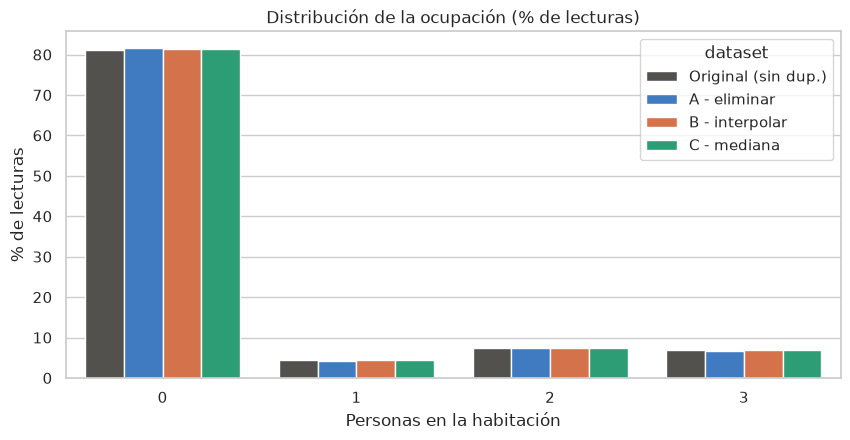

In [49]:
plot_df = target_pct.reset_index(names="ocupacion").melt(id_vars="ocupacion", var_name="dataset", value_name="pct")

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=plot_df, x="ocupacion", y="pct", hue="dataset", palette=PALETTE, ax=ax)
ax.set_title("Distribución de la ocupación (% de lecturas)")
ax.set_xlabel("Personas en la habitación")
ax.set_ylabel("% de lecturas")
save_figure("8_2_objetivo")
plt.show()

In [50]:
# Prueba chi-cuadrada de homogeneidad: ¿las proporciones de clase son iguales a las de la línea base?
ref_counts = datasets[REFERENCE][TARGET].value_counts().sort_index()
chi2_results = {}
for name in STRATEGIES:
    counts = datasets[name][TARGET].value_counts().reindex(ref_counts.index, fill_value=0)
    chi2, p, _, _ = stats.chi2_contingency(np.vstack([ref_counts.to_numpy(), counts.to_numpy()]))
    chi2_results[name] = p
    print(f"{name:15s} vs {REFERENCE}: chi2 = {chi2:6.2f}, p-value = {p:.3f}")

A - eliminar    vs Original (sin dup.): chi2 =   0.75, p-value = 0.861
B - interpolar  vs Original (sin dup.): chi2 =   0.05, p-value = 0.997
C - mediana     vs Original (sin dup.): chi2 =   0.03, p-value = 0.999


**Resultado.** Las tres estrategias conservan el desbalance del original (≈81% de lecturas con la
habitación vacía). Ninguna prueba chi-cuadrada encuentra diferencias (p = 0.861, 0.997 y 0.999):
la limpieza eliminó filas sin depender del número de ocupantes. A es la que más se aleja, porque
pierde un tercio de las filas.

#### 8.3 Analisis univariado

In [51]:
def univariate_summary(d):
    s = d[FEATURES]
    return pd.DataFrame({
        "media": s.mean(), "mediana": s.median(), "desv_est": s.std(),
        "min": s.min(), "max": s.max(), "asimetria": s.skew(), "curtosis": s.kurt(),
    })

univariate = pd.concat({name: univariate_summary(d) for name, d in datasets.items()}, axis=1)
univariate.xs("media", axis=1, level=1).round(3)

,Original (sin dup.),A - eliminar,B - interpolar,C - mediana
S1_Temp,25.454,25.450,25.454,25.452
S2_Temp,25.546,25.539,25.543,25.541
S3_Temp,25.057,25.052,25.056,25.054
S4_Temp,25.754,25.748,25.754,25.753
S1_Light,25.445,24.759,25.314,24.826
S2_Light,26.016,25.243,25.890,25.416
S3_Light,34.248,33.496,34.139,33.378
S4_Light,13.220,12.797,13.189,12.840
S1_Sound,0.168,0.174,0.175,0.174
S2_Sound,0.120,0.132,0.133,0.130


In [52]:
# Diferencia relativa (%) de la media y la desviación estándar contra la línea base
ref_stats = univariate_summary(datasets[REFERENCE])
rel_diff = {
    name: ((univariate_summary(datasets[name]) - ref_stats) / ref_stats.abs() * 100)[["media", "desv_est"]]
    for name in STRATEGIES
}
pd.concat(rel_diff, axis=1).round(1)

A - eliminar          B - interpolar          C - mediana         
                    media desv_est          media desv_est       media desv_est
S1_Temp              -0.0     -0.4           -0.0     -0.3        -0.0     -1.4
S2_Temp              -0.0     -1.2           -0.0     -1.1        -0.0     -1.9
S3_Temp              -0.0      0.1           -0.0     -0.2        -0.0     -1.3
S4_Temp              -0.0     -0.2            0.0     -0.2        -0.0     -1.2
S1_Light             -2.7     -1.2           -0.5     -0.2        -2.4     -0.9
S2_Light             -3.0     -1.4           -0.5     -0.3        -2.3     -0.9
S3_Light             -2.2     -0.5           -0.3     -0.2        -2.5     -0.9
S4_Light             -3.2     -1.0           -0.2     -0.0        -2.9     -0.8
S1_Sound              3.6     10.4            4.0     10.4         3.2      9.9
S2_Sound              9.9     26.1           10.4     24.3         8.7     23.2
S3_Sound              7.2     10.6            5.9      7.6         4.2      6.6
S4_Sound              7.5     66.1            7.5     60.7         6.8     59.9
S5_CO2               -0.1      0.1           -0.1     -0.4        -0.7     -1.4
S5_CO2_Slope       -142.6      1.3            1.4     -0.1        11.2     -1.1
S6_PIR               -1.3     -0.6            0.7      0.3        -1.6     -0.7
S7_PIR                1.8      0.8            0.3      0.1        -1.6     -0.7

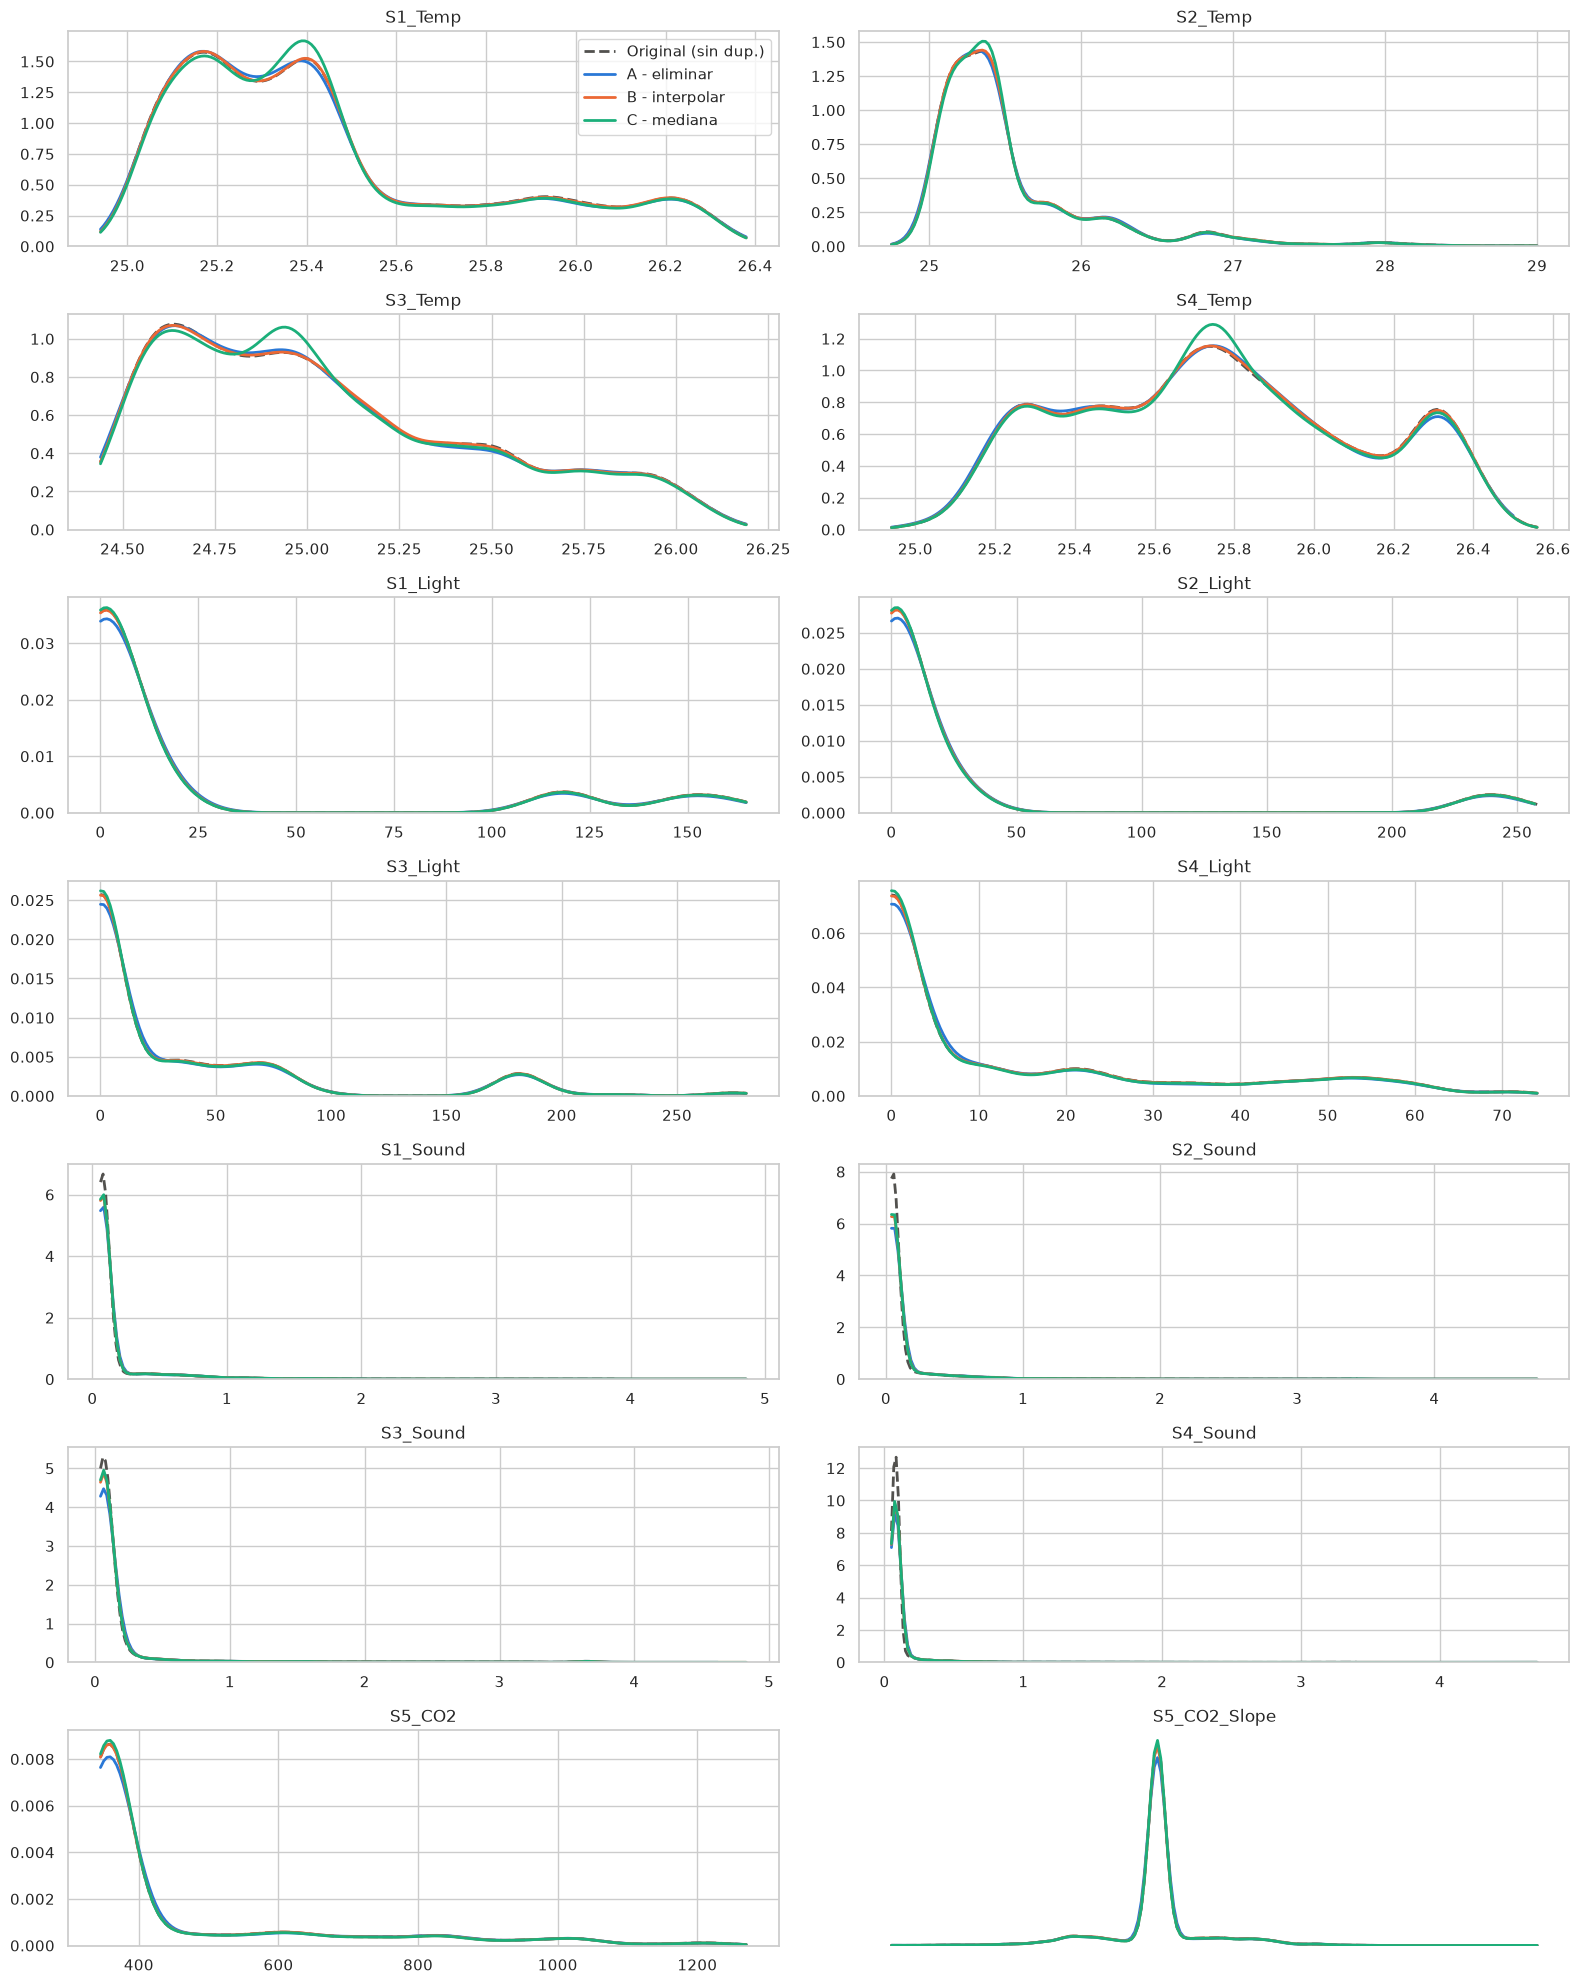

In [53]:
# Distribuciones superpuestas de las variables continuas (los PIR binarios se comparan en las tablas)
fig, axes = plt.subplots(7, 2, figsize=(16, 20))
for ax, col in zip(axes.flat, CONTINUOUS_COLS):
    for name, d in datasets.items():
        sns.kdeplot(d[col], ax=ax, color=PALETTE[name], linestyle=LINESTYLE[name], linewidth=2,
                    cut=0, label=name, warn_singular=False)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes.flat[0].legend()
axes.flat[-1].axis("off")
plt.tight_layout()
save_figure("8_3_distribuciones")
plt.show()

**Resultado.**
- **Medias.** Las de temperatura y CO2 casi no cambian en ninguna estrategia. En luz, A y C quedan
  2–3% por debajo del original y B solo 0.2–0.5%.
- **La firma de la mediana.** C reduce la desviación estándar de las temperaturas (−1.2% a −1.9%)
  y crea picos artificiales en su mediana, visibles en `S1_Temp`, `S3_Temp` y `S4_Temp`: el 1–2%
  de cada columna recibió exactamente el mismo valor. Las curvas de B quedan prácticamente encima
  de la línea base punteada.
- **Sonido.** Las tres estrategias tienen más dispersión que el original (+7% a +66%) y menos
  lecturas cerca de cero. Es el efecto de los ~135 valores de sonido corrompidos que la auditoría
  (sección 7) mostró que no se pudieron detectar; afecta a las tres por igual.
- **diferencia relativa.** El −142.6% de `S5_CO2_Slope` en A es engañoso: la media
  del original es casi cero (−0.005), así que cualquier cambio mínimo parece enorme en porcentaje.
  La diferencia estandarizada de medias de la sección 8.7 es la medida adecuada.

#### 8.4 Outliers potenciales (regla IQR)

In [54]:
def iqr_outlier_pct(d):
    out = {}
    for col in FEATURES:
        q1, q3 = d[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        out[col] = 100 * ((d[col] < q1 - 1.5 * iqr) | (d[col] > q3 + 1.5 * iqr)).mean()
    return pd.Series(out)

pd.DataFrame({name: iqr_outlier_pct(d) for name, d in datasets.items()}).round(2)

,Original (sin dup.),A - eliminar,B - interpolar,C - mediana
S1_Temp,1.60,1.56,1.53,1.53
S2_Temp,9.36,8.97,9.16,8.98
S3_Temp,0.00,0.00,0.00,0.00
S4_Temp,0.00,0.00,0.00,0.00
S1_Light,16.94,16.51,16.85,16.53
S2_Light,10.04,10.76,10.01,10.85
S3_Light,9.38,9.29,9.33,9.13
S4_Light,5.36,7.88,5.35,8.01
S1_Sound,17.49,17.35,17.77,17.39
S2_Sound,16.81,16.94,17.28,16.88


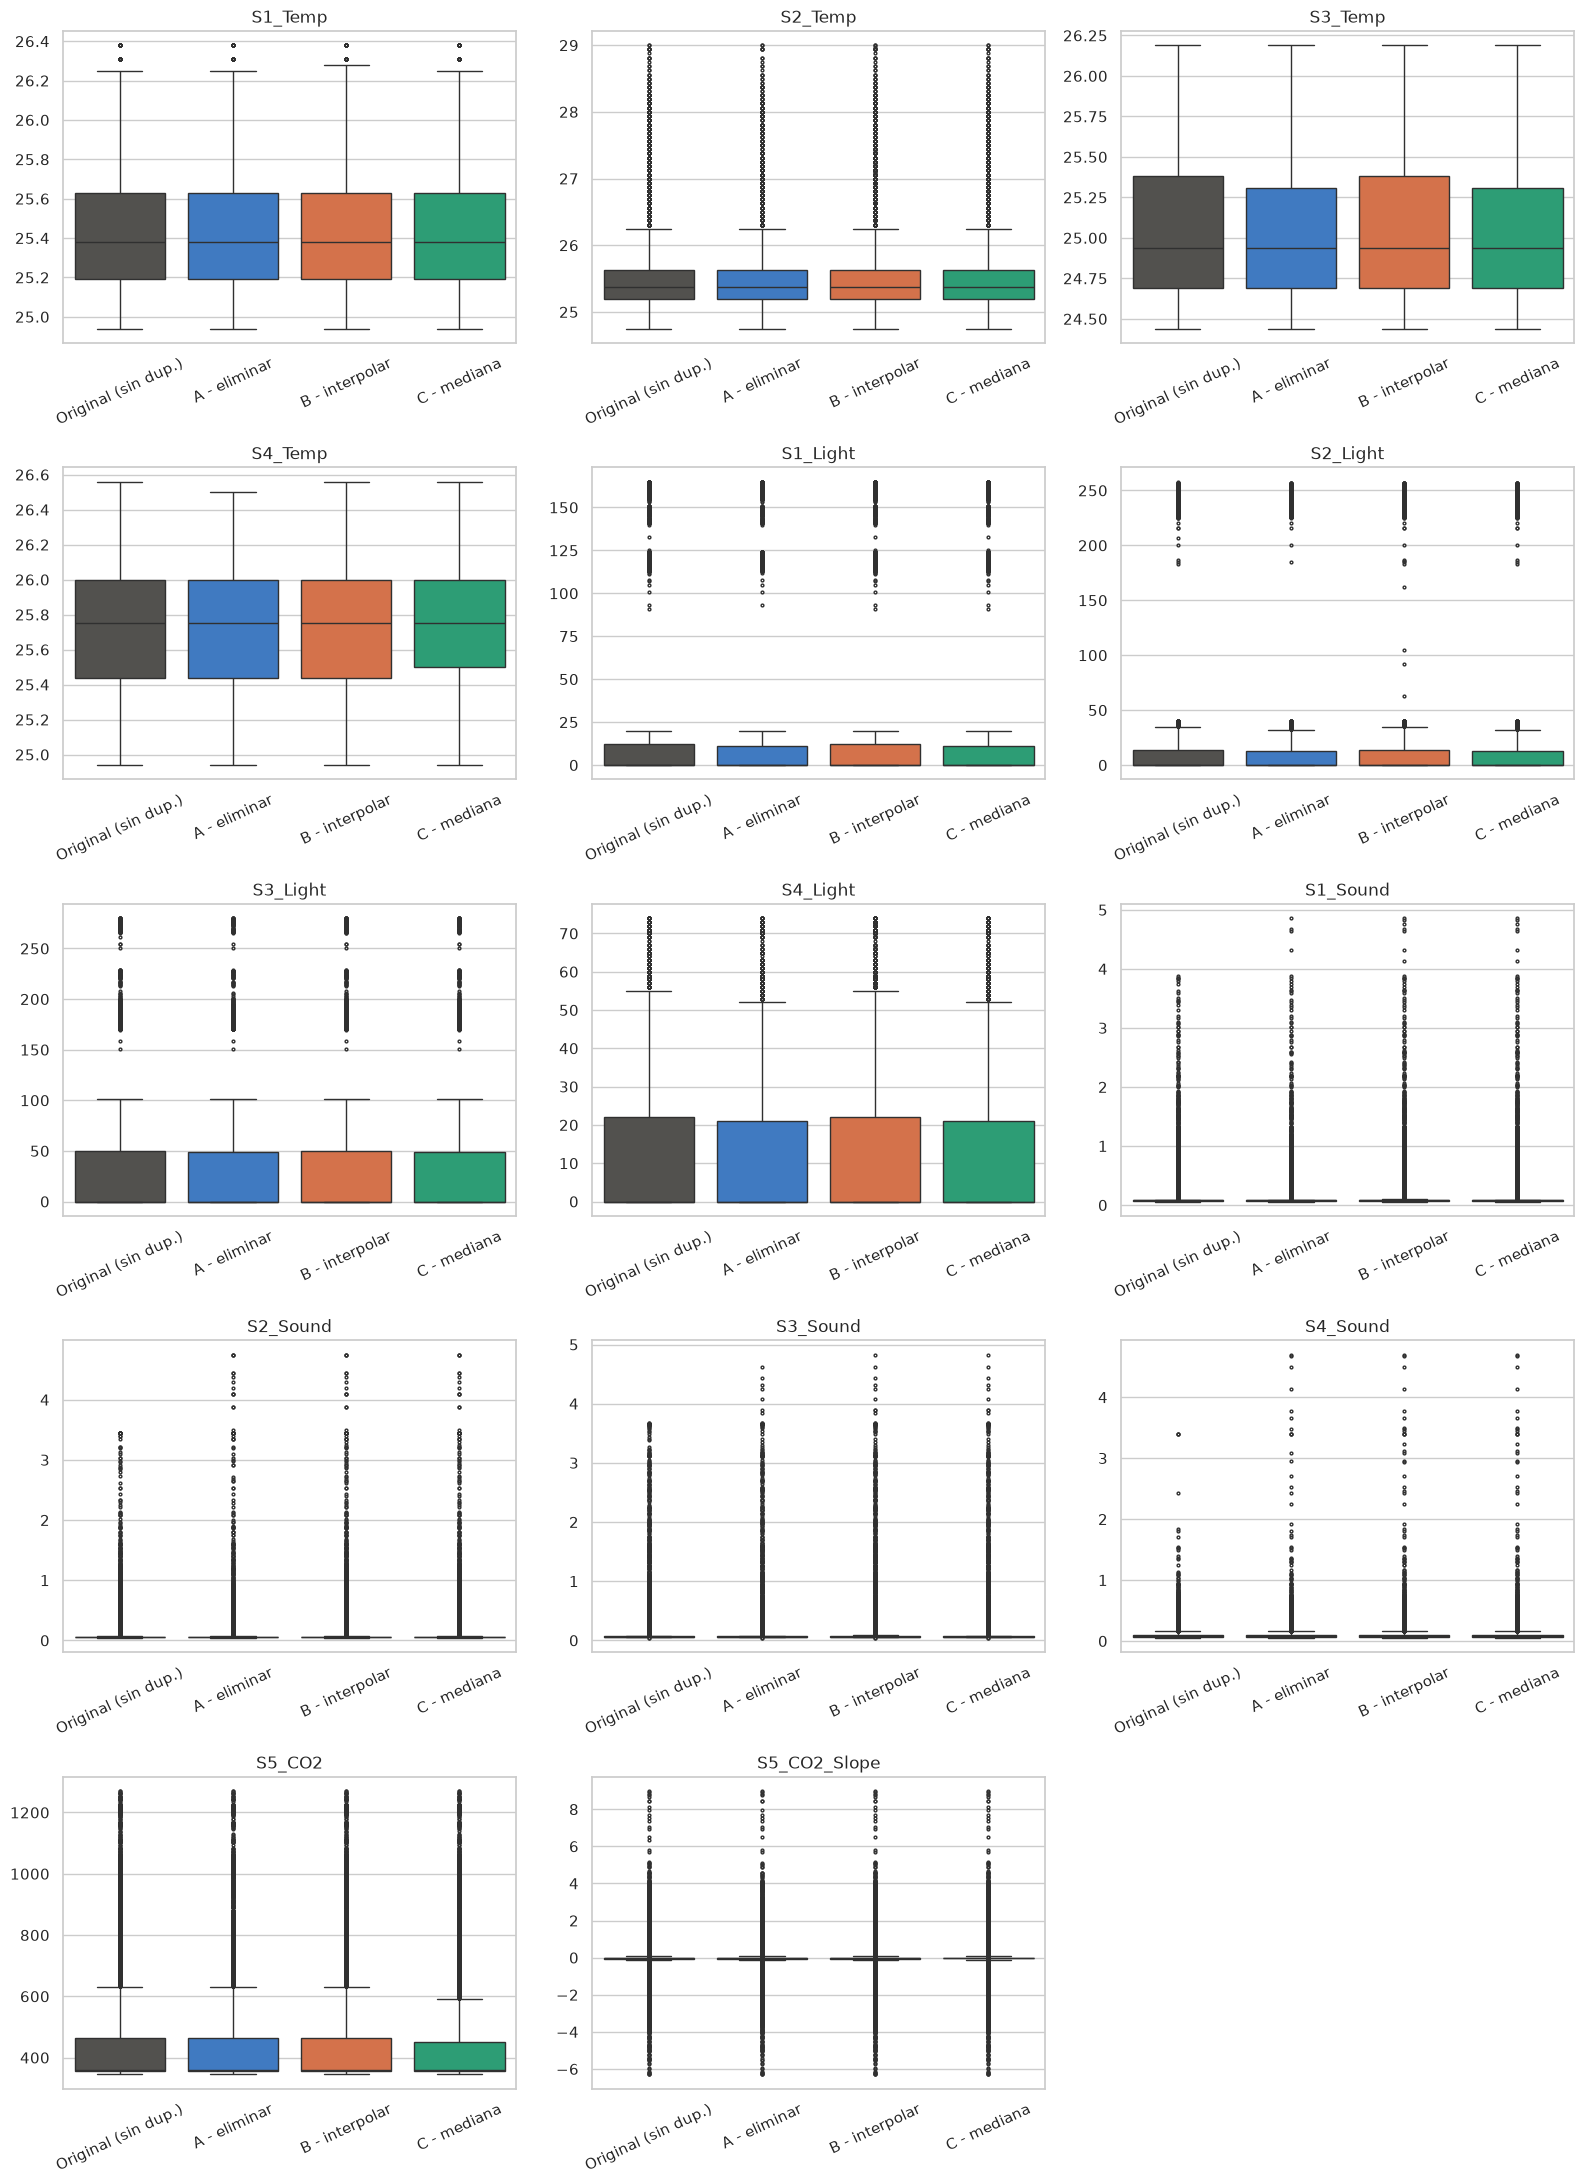

In [55]:
# Boxplots lado a lado: dispersión y outliers potenciales de cada dataset
long_df = pd.concat([d[CONTINUOUS_COLS].assign(dataset=name) for name, d in datasets.items()], ignore_index=True)

fig, axes = plt.subplots(5, 3, figsize=(16, 22))
for ax, col in zip(axes.flat, CONTINUOUS_COLS):
    sns.boxplot(data=long_df, x="dataset", y=col, hue="dataset", palette=PALETTE, ax=ax,
                legend=False, fliersize=2, linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=25)
axes.flat[-1].axis("off")
plt.tight_layout()
save_figure("8_4_boxplots")
plt.show()

**Resultado.** El porcentaje de outliers potenciales es parecido en casi todas las variables: la
limpieza quitó los errores, pero no las colas naturales (lecturas con gente y luces encendidas).
Los boxplots muestran por qué hay dos excepciones:
- En `S4_Light`, A y C bajan el tercer cuartil (de 22 a 21 lux) y acortan el bigote superior
  (de 55 a 52), así que más lecturas reales quedan fuera: los outliers suben de 5.4% a 7.9–8.0%.
  B reproduce la caja del original y su 5.4%.
- En `S5_CO2`, la caja de C es más estrecha: al rellenar 241 celdas con la mediana (360 ppm), el
  rango intercuartílico se encoge y los outliers suben de 16.4% a 18.5%.

En las cuatro variables de sonido, las tres estrategias tienen puntos por encima del máximo del
original (hasta ~4.8 V frente a ~3.9 V): son los valores corrompidos no detectados de la sección 7.
En todas las demás variables, la caja de B es idéntica a la del original.

#### 8.5 Relacion con la variable objetivo

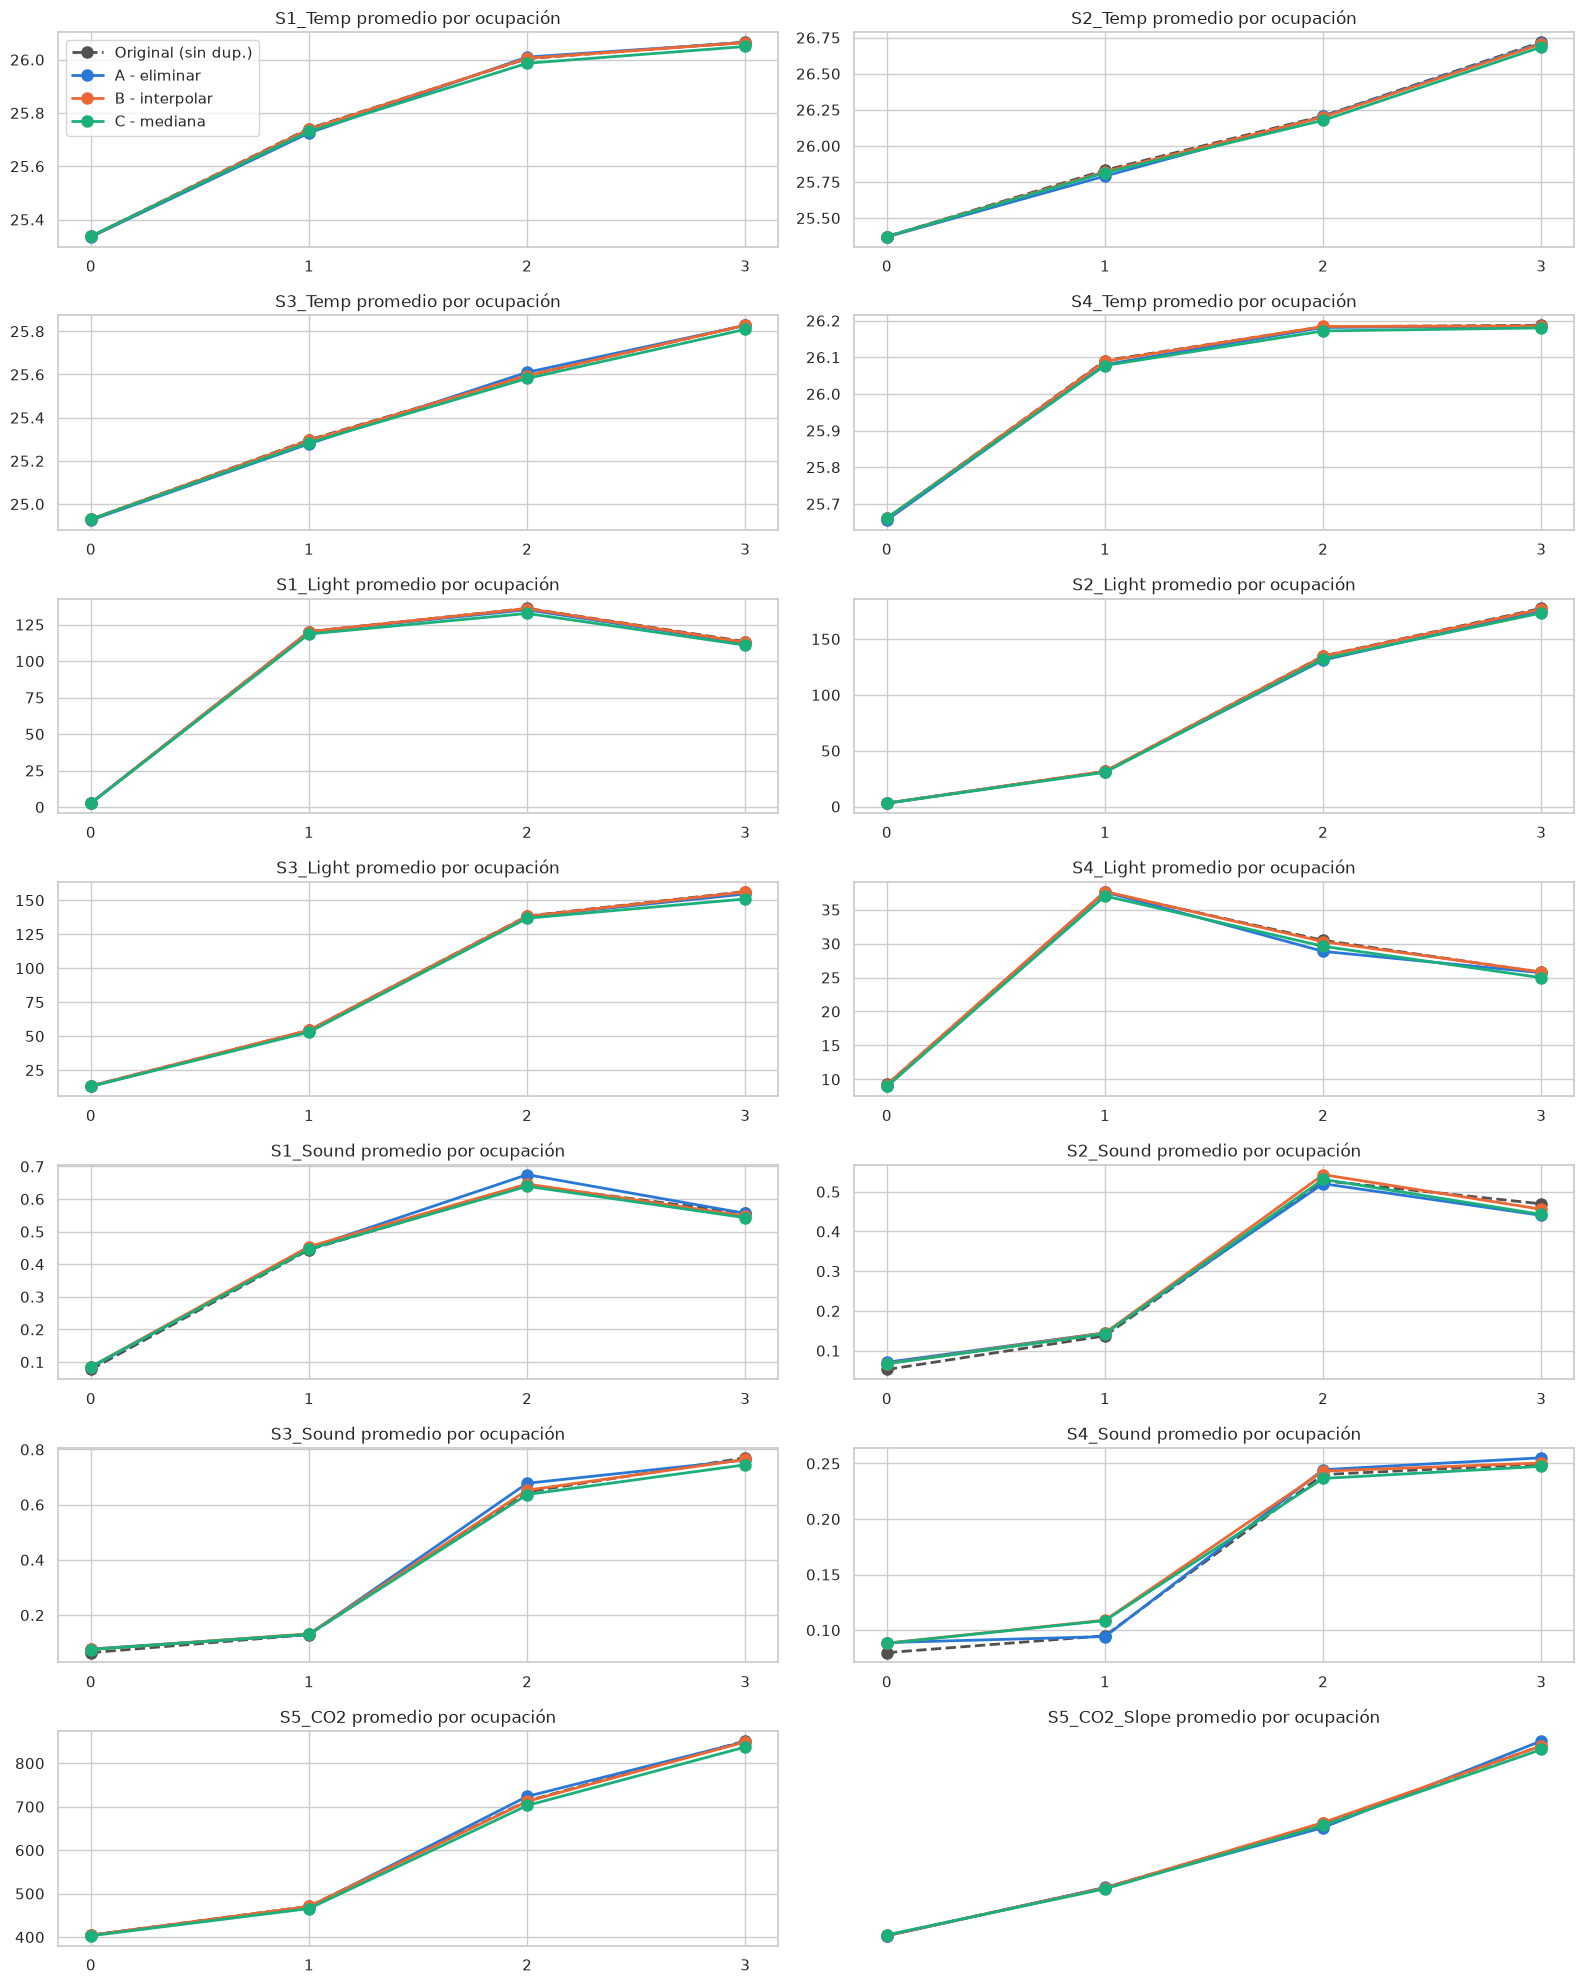

In [56]:
# Promedio de cada variable por número de ocupantes: una línea por dataset
means_by_occ = pd.concat(
    [d.groupby(TARGET)[CONTINUOUS_COLS].mean().assign(dataset=name).reset_index()
     for name, d in datasets.items()],
    ignore_index=True,
)
fig, axes = plt.subplots(7, 2, figsize=(16, 20))
for ax, col in zip(axes.flat, CONTINUOUS_COLS):
    for name in datasets:
        part = means_by_occ[means_by_occ["dataset"] == name]
        ax.plot(part[TARGET], part[col], color=PALETTE[name], linestyle=LINESTYLE[name],
                marker="o", markersize=8, linewidth=2, label=name)
    ax.set_title(f"{col} promedio por ocupación")
    ax.set_xticks([0, 1, 2, 3])
axes.flat[0].legend()
axes.flat[-1].axis("off")
plt.tight_layout()
save_figure("8_5_relacion_objetivo")
plt.show()

In [57]:
# ¿La imputación es coherente con el contexto? Lecturas con gente en la habitación
LIGHT_COLS = ["S1_Light", "S2_Light", "S3_Light", "S4_Light"]
context = pd.DataFrame({
    name: {
        "lecturas_con_gente": int((d[TARGET] > 0).sum()),
        "con_gente_y_S1_Light_0": int(((d[TARGET] > 0) & (d["S1_Light"] == 0)).sum()),
        "pct_con_gente_y_S1_Light_0": 100 * ((d[TARGET] > 0) & (d["S1_Light"] == 0)).sum() / (d[TARGET] > 0).sum(),
        "luz_media_con_gente": d.loc[d[TARGET] > 0, LIGHT_COLS].mean().mean(),
        "CO2_medio_con_gente": d.loc[d[TARGET] > 0, "S5_CO2"].mean(),
    }
    for name, d in datasets.items()
}).T
context.round(2)

,lecturas_con_gente,con_gente_y_S1_Light_0,pct_con_gente_y_S1_Light_0,luz_media_con_gente,CO2_medio_con_gente
Original (sin dup.),1901.0,2.0,0.11,101.11,705.03
A - eliminar,1263.0,1.0,0.08,100.42,710.65
B - interpolar,1820.0,2.0,0.11,101.00,704.10
C - mediana,1823.0,37.0,2.03,98.93,694.91


**Resultado.** Las tendencias se conservan en las tres estrategias: más ocupantes, más luz, más
temperatura y más CO2. La diferencia está en la coherencia con el contexto. En el original solo 2
de 1,901 lecturas con gente tienen `S1_Light` = 0 (0.11%); B conserva exactamente esa proporción,
pero C sube a 37 (2.03%), porque la mediana rellenó con "luz apagada" lecturas en las que había
gente. Lo mismo ocurre con el CO2 promedio con gente: 705 ppm en el original, 704 en B y 695 en C.
C debilita justamente la relación que un modelo usaría para estimar la ocupación.

#### 8.6 Correlaciones

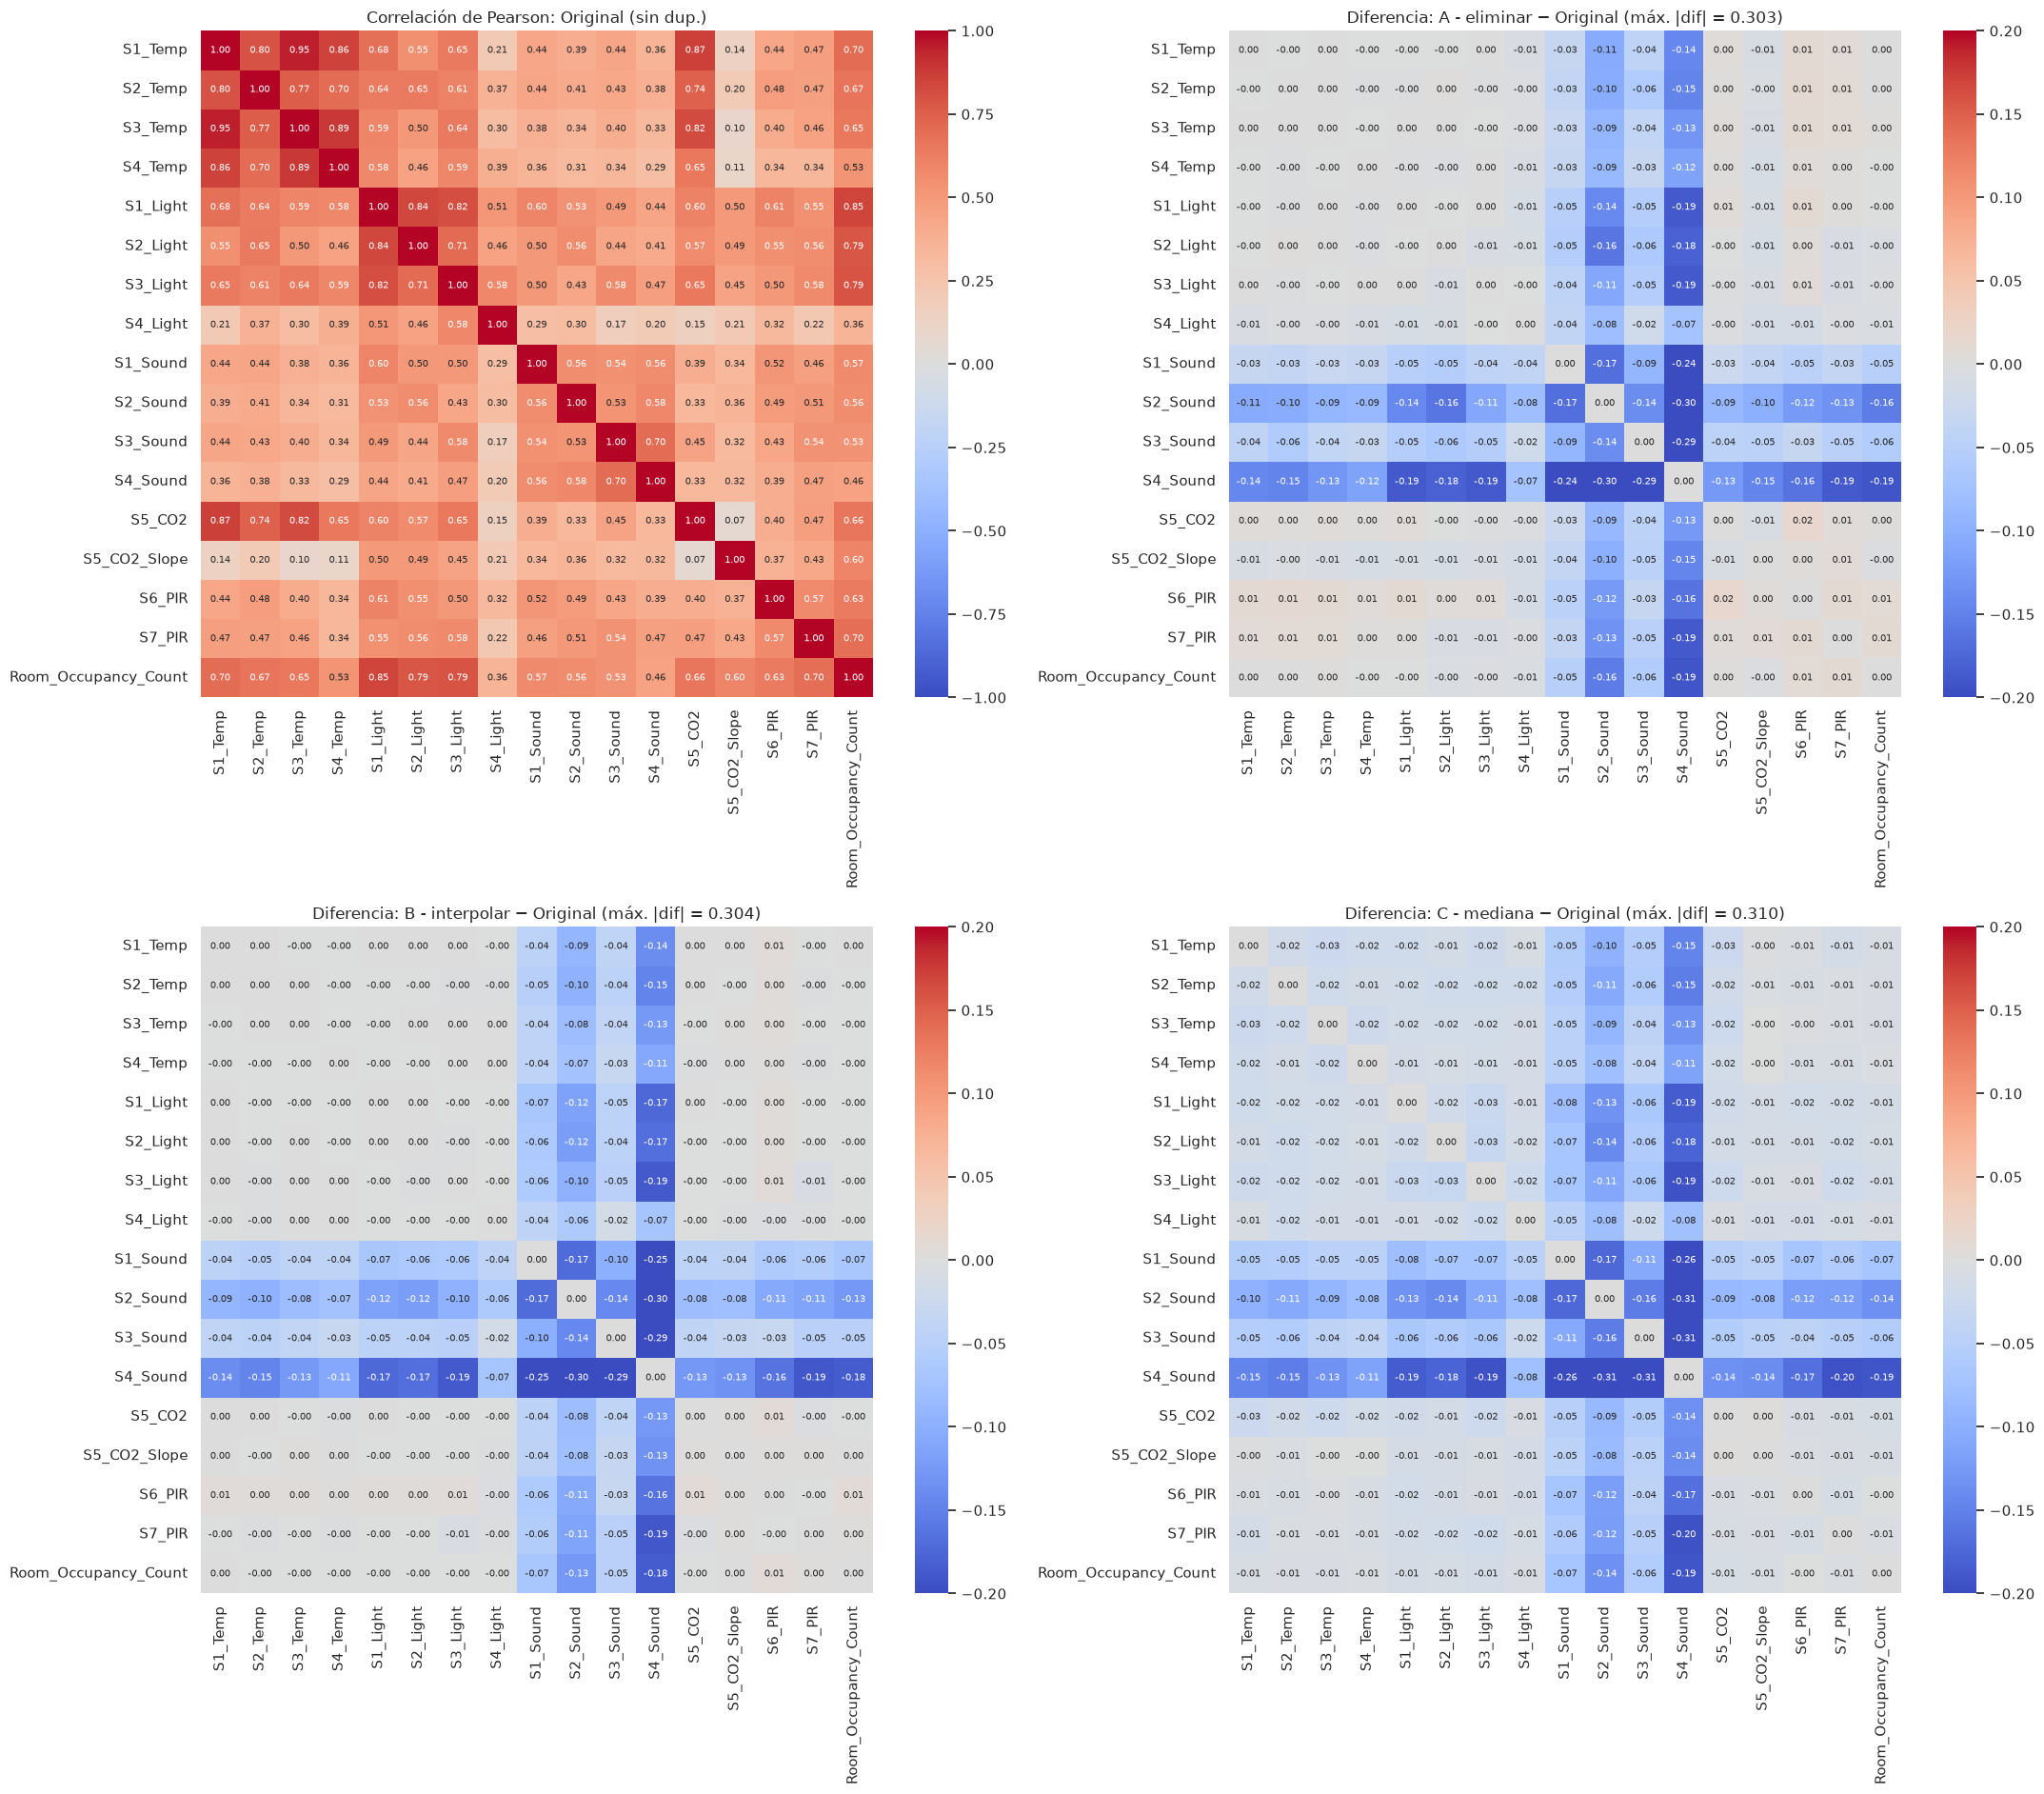

In [58]:
corr_cols = FEATURES + [TARGET]
ref_corr = datasets[REFERENCE][corr_cols].corr()

fig, axes = plt.subplots(2, 2, figsize=(22, 19))
sns.heatmap(ref_corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=axes[0, 0])
axes[0, 0].set_title(f"Correlación de Pearson: {REFERENCE}")
for ax, name in zip(axes.flat[1:], STRATEGIES):
    diff = datasets[name][corr_cols].corr() - ref_corr
    sns.heatmap(diff, cmap="coolwarm", center=0, vmin=-0.2, vmax=0.2, annot=True, fmt=".2f",
                annot_kws={"size": 7}, ax=ax)
    ax.set_title(f"Diferencia: {name} − Original (máx. |dif| = {diff.abs().max().max():.3f})")
plt.tight_layout()
save_figure("8_6_correlaciones")
plt.show()

In [59]:
# Correlación de cada variable con el objetivo
target_corr = pd.DataFrame({name: d[corr_cols].corr()[TARGET].drop(TARGET) for name, d in datasets.items()})
target_corr.sort_values(REFERENCE, key=lambda s: s.abs(), ascending=False).round(3)

,Original (sin dup.),A - eliminar,B - interpolar,C - mediana
S1_Light,0.849,0.848,0.848,0.837
S3_Light,0.793,0.789,0.792,0.779
S2_Light,0.789,0.784,0.788,0.778
S1_Temp,0.701,0.702,0.701,0.692
S7_PIR,0.695,0.705,0.697,0.690
S2_Temp,0.671,0.672,0.671,0.664
S5_CO2,0.660,0.662,0.660,0.650
S3_Temp,0.652,0.654,0.652,0.646
S6_PIR,0.633,0.641,0.641,0.632
S5_CO2_Slope,0.601,0.597,0.601,0.593


In [60]:
# ¿La limpieza cambia qué variables parecen más importantes?
top_k = 5
pd.DataFrame(
    {name: target_corr[name].abs().sort_values(ascending=False).head(top_k).index.tolist() for name in datasets},
    index=[f"#{i + 1}" for i in range(top_k)],
)

,Original (sin dup.),A - eliminar,B - interpolar,C - mediana
#1,S1_Light,S1_Light,S1_Light,S1_Light
#2,S3_Light,S3_Light,S3_Light,S3_Light
#3,S2_Light,S2_Light,S2_Light,S2_Light
#4,S1_Temp,S7_PIR,S1_Temp,S1_Temp
#5,S7_PIR,S1_Temp,S7_PIR,S7_PIR


**Resultado.** Las correlaciones de luz, temperatura, CO2 y PIR con el objetivo se conservan en las
tres estrategias, con diferencias de centésimas. Las cinco variables más relacionadas con la ocupación
quedan en el mismo orden que el original en B y C; A intercambia los lugares 4 y 5. La diferencia
máxima (≈0.30 en las tres) viene **solo del sonido**: los valores corrompidos no detectados debilitan
su relación con la ocupación (p. ej. `S4_Sound` pasa de 0.46 a ≈0.27). Fuera del sonido, la mayor
diferencia es 0.008 en B, 0.016 en A y 0.030 en C.

#### 8.7 Pruebas formales de similitud

Las gráficas convencen, pero son subjetivas. Estas métricas hacen medible la comparación:

| Métrica | Qué mide | Criterio de "equivalente" |
|---|---|---|
| **Kolmogorov–Smirnov (KS)** | La mayor distancia entre las dos distribuciones acumuladas | p-value > 0.05 |
| **Diferencia estandarizada de medias (SMD)** | Desplazamiento de la media, en desviaciones estándar del original | \|SMD\| < 0.1 |
| **Razón de varianzas** | Dispersión limpia / dispersión original | entre 0.9 y 1.1 |
| **Chi-cuadrada** (sección 8.2) | Igualdad de las proporciones del objetivo | p-value > 0.05 |
| **Diferencia de correlaciones** (sección 8.6) | Cambio máximo en la matriz de correlaciones | cercana a 0 |

> KS es conservadora con variables discretas como los PIR por los empates; para el objetivo, la
> prueba adecuada es la chi-cuadrada.

In [61]:
def distribution_tests(name):
    """KS, SMD y razón de varianzas de cada variable de una estrategia contra la línea base."""
    ref, d = datasets[REFERENCE], datasets[name]
    rows = []
    for col in FEATURES:
        ks = stats.ks_2samp(ref[col], d[col])
        rows.append({
            "variable": col,
            "ks_stat": ks.statistic,
            "ks_pvalue": ks.pvalue,
            "smd": (d[col].mean() - ref[col].mean()) / ref[col].std(),
            "razon_varianzas": d[col].var() / ref[col].var(),
        })
    out = pd.DataFrame(rows).set_index("variable")
    out["equivalente"] = ((out["ks_pvalue"] > 0.05) & (out["smd"].abs() < 0.1)
                          & out["razon_varianzas"].between(0.9, 1.1))
    return out

tests = {name: distribution_tests(name) for name in STRATEGIES}
for name in STRATEGIES:
    print(name)
    display(tests[name].round(4))

A - eliminar


,ks_stat,ks_pvalue,smd,razon_varianzas,equivalente
variable,,,,,
S1_Temp,0.0099,0.8176,-0.0109,0.9927,True
S2_Temp,0.0100,0.8023,-0.0122,0.9755,True
S3_Temp,0.0087,0.9112,-0.0110,1.0023,True
S4_Temp,0.0083,0.9381,-0.0166,0.9956,True
S1_Light,0.0103,0.7742,-0.0134,0.9762,True
S2_Light,0.0105,0.7549,-0.0115,0.9718,True
S3_Light,0.0117,0.6258,-0.0129,0.9892,True
S4_Light,0.0125,0.5441,-0.0216,0.9794,True
S1_Sound,0.0041,1.0000,0.0192,1.2194,False


B - interpolar


,ks_stat,ks_pvalue,smd,razon_varianzas,equivalente
variable,,,,,
S1_Temp,0.0017,1.0000,-0.0014,0.9947,True
S2_Temp,0.0022,1.0000,-0.0052,0.9783,True
S3_Temp,0.0019,1.0000,-0.0005,0.9958,True
S4_Temp,0.0025,1.0000,0.0004,0.9960,True
S1_Light,0.0018,1.0000,-0.0026,0.9950,True
S2_Light,0.0015,1.0000,-0.0019,0.9939,True
S3_Light,0.0018,1.0000,-0.0019,0.9966,True
S4_Light,0.0017,1.0000,-0.0016,1.0000,True
S1_Sound,0.0040,1.0000,0.0213,1.2195,False


C - mediana


,ks_stat,ks_pvalue,smd,razon_varianzas,equivalente
variable,,,,,
S1_Temp,0.0125,0.4177,-0.0059,0.9720,True
S2_Temp,0.0128,0.3907,-0.0091,0.9621,True
S3_Temp,0.0124,0.4315,-0.0069,0.9745,True
S4_Temp,0.0121,0.4628,-0.0018,0.9770,True
S1_Light,0.0120,0.4638,-0.0121,0.9823,True
S2_Light,0.0124,0.4311,-0.0089,0.9819,True
S3_Light,0.0117,0.5053,-0.0149,0.9819,True
S4_Light,0.0124,0.4242,-0.0194,0.9836,True
S1_Sound,0.0107,0.6219,0.0170,1.2084,False


In [62]:
# Tabla resumen: las tres estrategias contra la línea base
SOUND_COLS = ["S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound"]
NON_SOUND = [c for c in corr_cols if c not in SOUND_COLS]

scorecard = []
for name in STRATEGIES:
    t = tests[name]
    corr_diff = datasets[name][corr_cols].corr() - ref_corr
    scorecard.append({
        "estrategia": name,
        "filas": len(datasets[name]),
        "chi2_p_objetivo": chi2_results[name],
        "variables_equivalentes": f"{int(t['equivalente'].sum())}/{len(t)}",
        "ks_stat_medio": t["ks_stat"].mean(),
        "ks_p_minimo": t["ks_pvalue"].min(),
        "smd_medio_abs": t["smd"].abs().mean(),
        "razon_varianzas_rango": f"{t['razon_varianzas'].min():.3f} - {t['razon_varianzas'].max():.3f}",
        "dif_corr_max_abs": corr_diff.abs().max().max(),
        "dif_corr_max_abs_sin_sonido": corr_diff.loc[NON_SOUND, NON_SOUND].abs().max().max(),
    })
scorecard_df = pd.DataFrame(scorecard).set_index("estrategia")
scorecard_df.round(4)

,filas,chi2_p_objetivo,variables_equivalentes,ks_stat_medio,ks_p_minimo,smd_medio_abs,razon_varianzas_rango,dif_corr_max_abs,dif_corr_max_abs_sin_sonido
estrategia,,,,,,,,,
A - eliminar,6876,0.8614,12/16,0.0072,0.5441,0.0177,0.972 - 2.758,0.3027,0.0159
B - interpolar,9739,0.9968,12/16,0.0023,0.9980,0.0111,0.978 - 2.583,0.3036,0.0075
C - mediana,9742,0.9985,12/16,0.0095,0.3907,0.0148,0.962 - 2.558,0.3101,0.0299


**Resultado.**

| vs. Original (sin dup.) | Filas | Equivalentes | KS medio | KS p mínimo | \|SMD\| medio | Máx. \|Δcorr\| sin sonido |
|---|---|---|---|---|---|---|
| A - eliminar | 6,876 | 12/16 | 0.0072 | 0.544 | 0.0177 | 0.016 |
| **B - interpolar** | **9,739** | 12/16 | **0.0023** | **0.998** | **0.0111** | **0.008** |
| C - mediana | 9,742 | 12/16 | 0.0095 | 0.391 | 0.0148 | 0.030 |

- **Las tres estrategias fallan en las mismas 4 variables: los 4 sensores de sonido.** Su media y su
  forma se parecen al original (KS p > 0.6, \|SMD\| < 0.07), pero su varianza es entre 1.14 y 2.76
  veces mayor. No es un defecto de ninguna estrategia: son los valores corrompidos que ninguna
  regla pudo detectar (sección 7), y llegan intactos a las tres.
- **En todo lo demás, B es la más parecida al original en todas las métricas**: la menor distancia
  KS (tres veces menor que A y cuatro veces menor que C), el menor desplazamiento de medias y la
  menor diferencia de correlaciones, conservando el 96% de las lecturas.
- **A** es fiel en las variables pero pierde un tercio de los datos y deja huecos en la serie.
- **C** pasa los criterios de equivalencia, pero tiene la mayor distancia KS, el mayor cambio en
  las correlaciones y las contradicciones con el contexto de la sección 8.5.

### 9. Conclusiones

#### Problemas encontrados y cómo se corrigieron

| Prueba | Problema | Magnitud | Acción |
|---|---|---|---|
| T1 | Columna de ruido `mixed_type_col` | 1 columna | Eliminada |
| T3 | Espacios al inicio o al final | 9,766 celdas (5%) | Quitar espacios en todas las columnas |
| T4, T5 | Tokens inválidos y celdas vacías | 2,810 celdas | Convertidos a faltante |
| T6 | Valores físicamente imposibles | 994 celdas | Convertidos a faltante |
| T8 | Objetivo faltante o fuera de 0–3 | 215 filas | Eliminadas (una etiqueta nunca se imputa) |
| T7a | Lecturas sin marca de tiempo válida | 192 filas | Eliminadas |
| T9 | Lecturas registradas dos veces | 182 copias | Combinadas por marca de tiempo; 66 celdas recuperadas |
| T10 | Picos aislados dentro del rango | 291 celdas | Convertidos a faltante |
| T7b, T7c | Movimiento sin ocupación; sensores de temperatura | 23 lecturas; 0 | Ninguna acción: comportamiento físico normal |

Las pruebas detectaron el **96.3%** de las celdas corrompidas con solo 2 falsos positivos (sección 7).
Al final de los pasos compartidos, todos los problemas se redujeron a faltantes en el 29.4% de las filas.

#### ¿Qué estrategia preserva mejor la información?

| vs. Original (sin dup.) | Filas conservadas | KS medio | \|SMD\| medio | Máx. \|Δcorr\| sin sonido | Lecturas con gente y luz 0 |
|---|---|---|---|---|---|
| A - eliminar | 6,876 (67.9%) | 0.0072 | 0.0177 | 0.016 | 1 |
| **B - interpolar** | **9,739 (96.1%)** | **0.0023** | **0.0111** | **0.008** | **2 (igual que el original)** |
| C - mediana | 9,742 (96.2%) | 0.0095 | 0.0148 | 0.030 | 37 |

**La estrategia B (interpolación temporal) es la que mejor preserva la información.** Es la más
parecida al original en todas las métricas que distinguen a las estrategias, y conserva el 96% de
las lecturas. Funciona porque aprovecha la naturaleza de los datos: con lecturas cada 30 segundos,
los valores vecinos casi no cambian, así que estimar un faltante a partir de ellos es mucho más
preciso que usar un valor global.

- **A** conserva solo mediciones reales y sus distribuciones son fieles, pero pierde un tercio de
  las lecturas y deja huecos en la serie de tiempo, un problema para cualquier modelo temporal.
- **C** pasa la validación y los criterios de equivalencia, pero rellena con valores de habitación
  vacía (luz 0 lux, CO2 360 ppm) lecturas en las que había gente: multiplica por 18 las
  contradicciones entre sensores y ocupación, crea picos artificiales en las distribuciones y
  debilita todas las correlaciones. Es un ejemplo de que un dataset **válido** no es necesariamente
  **correcto**.
- Las tres conservan las proporciones del objetivo (chi-cuadrada p > 0.86).

#### Limitaciones

- **Sonido no detectable.** Unas 135 celdas de sonido corrompidas parecen ruido real (una voz, un
  golpe) y ninguna regla pudo separarlas. Llegan a las tres estrategias: la varianza del sonido
  queda entre 1.14 y 2.76 veces la del original y su correlación con la ocupación baja (p. ej.
  `S4_Sound`, de 0.46 a ≈0.27). Por eso las cuatro variables de sonido no pasan la prueba de
  equivalencia en ninguna estrategia.
- **Conflictos entre copias.** En 12 celdas, dos copias de la misma lectura traían valores válidos
  distintos; se conservó la primera sin poder saber cuál era la correcta.
- **Supuestos del contrato.** Algunos límites son decisiones del analista, no de la documentación:
  el ADC de 5 V del sonido, el rango de la pendiente del CO2 y las tolerancias de T10 (50 lux,
  100 ppm). Otros valores elegirían otro equilibrio entre detección y falsas alarmas.
- **Alcance de T10.** No puede evaluar lecturas sin marca de tiempo, y en 2 ocasiones confundió un
  encendido real de luz con un pico.
- **Uso en producción.** La interpolación usa la lectura siguiente, que en tiempo real todavía no
  existe; un sistema en línea tendría que usar solo la anterior (*forward fill*). La mediana de C
  tendría que calcularse solo con datos de entrenamiento.
- **La auditoría solo fue posible porque el ejercicio es sintético.** En un proyecto real no
  habría original contra qué comparar, y la calidad de la limpieza dependería por completo de las
  pruebas y del contrato de datos.